In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import glob
import pickle
import threading
import traceback
from concurrent.futures import ThreadPoolExecutor, as_completed
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.layers import ELU1
from digitalbat.training.trainer import bat_former_trainer, finetune_readout_trainer
from digitalbat.utility.utils import set_random_state, poisson_fde_population, corr


In [2]:
SEED = 1
WD_GRID = [0.01, 0.1]
WD_SCRATCH_GRID = [0.01, 0.1, 1.0]
DEVICE = 'cuda'
LR = 1e-2
CORE_LR_FRAC = 0.1                 # lowlr core LR = CORE_LR_FRAC * LR

# One epoch budget for every mode; bumped well above what early stopping
# (patience = EARLY_STOP_PATIENCE) ever needs, so every model trains to
# convergence rather than hitting the cap.
N_EPOCHS = 10000
EARLY_STOP_PATIENCE = 100

# Parallel-within-GPU training. Tune based on `nvidia-smi` VRAM headroom.
MAX_WORKERS = 32

OUT_ROOT = os.path.abspath('./out/transfer')
TWOXFIVE_DIR = os.path.join(OUT_ROOT, 'twoxfive')
SCRATCH_LOWLR_DIR = os.path.join(OUT_ROOT, 'scratch_lowlr')
for d in (OUT_ROOT, TWOXFIVE_DIR, SCRATCH_LOWLR_DIR):
    os.makedirs(d, exist_ok=True)

set_random_state(SEED)

# Toggle synthetic-train dataloader build.  Currently no downstream cell in
# this notebook trains on synthetic data — set to True only if you wire one
# in via `mode_dataloaders[mode]` inside `_train_one`.
RUN_SYNTHETIC = False
RUN_SYNTHETIC_TRAJ = False  # trajectory-specific per-cluster rate maps; same plumbing as RUN_SYNTHETIC.
SYNTHETIC_TRAJ_MIN_CLUSTER_SIZE = 3


# Dataloader (all 18 sessions)

In [3]:
data_config = dict(
    use_speed_head_dir = False,
    use_IMU_flag = False,
    use_click_flag = False,
    use_LFP_flag = False,
    use_ripple_flag = False,
    only_flight_flag = True,
    firing_rate_criterion_flag = True,
    max_acceleration = 40,
    no_3d_location = False,
    spike_count_flag = True,
    bin_width = 0.10,
    split_flights_for_train = 'random',
    type_train_num = 1,
    type_valid_num = 1,
    special_id_count_thresh = 3,
    only_use_special_id_4train_flag = False,
    shuffle_flag = True,
    time_shuffle_for_trajecotry_flag = False,
    split_each_trajectory_flag = True,
    window_size = None,
    stride_train = None,
    stride_test = None,
    batch_size_train = None,
    batch_size_test = None,
    session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209',
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',
        'Dataset_1_32622_231007',
        'Dataset_2_14611_231208',
        'Dataset_2_14611_231209',
        'Dataset_3_00000_240402',
        'Dataset_3_00000_240403',
        'Dataset_3_00000_240404',
        'Dataset_3_00000_240405',
        'Dataset_3_29959_240405',
    ],
    parent_folder = '/mnt/s5/Adam/Angelo/NP_datasets/',
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'Loaded {len(unit_num_dict)} sessions, behavior_dim={behavior_dim}')
print(f'Units per session: {unit_num_dict}')

  Acceleration filter: removed 1/37 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
Loaded 18 sessions, behavior_dim=3
Units per session: {'Dataset_3_14543_240419': 204, 'Dataset_3_14543_240420': 77, 'Dataset_3_14543_240421': 65, 'Dataset_3_29959_240402': 266, 'Dataset_3_29959_240403': 149, 'Dataset_3_29959_240404': 121, 'Dataset_2_14445_231208': 155, 'Dataset_2_14445_231209': 102, 'Dataset_1_32622_231009':

In [ ]:
# Synthetic-train dataloaders share the same valid/test as `dataloaders`
# (by reference); only `train` spikes are Poisson samples from a smoothed
# 3D rate map fit on real training data.  Pass `syn_dataloaders` into any
# trainer to ablate long-range temporal dependencies.
if RUN_SYNTHETIC:
    from digitalbat.datasets.synthetic import make_synthetic_train_dataloaders
    syn_dataloaders, simulators = make_synthetic_train_dataloaders(
        dataloaders, meta_info_dict, dt=data_config['bin_width'], seed=SEED)
    assert syn_dataloaders['valid'] is dataloaders['valid']
    assert syn_dataloaders['test'] is dataloaders['test']
else:
    syn_dataloaders, simulators = None, None

# Trajectory-specific variant: per-flight-cluster rate maps.  Same
# shape contract as `syn_dataloaders`; route through `mode_dataloaders`
# if downstream training is wired up.
if RUN_SYNTHETIC_TRAJ:
    from digitalbat.datasets.synthetic import make_synthetic_train_dataloaders_traj
    syn_traj_dataloaders, simulators_traj = make_synthetic_train_dataloaders_traj(
        dataloaders, meta_info_dict, dt=data_config['bin_width'],
        min_cluster_size=SYNTHETIC_TRAJ_MIN_CLUSTER_SIZE, seed=SEED)
    assert syn_traj_dataloaders['valid'] is dataloaders['valid']
    assert syn_traj_dataloaders['test'] is dataloaders['test']
else:
    syn_traj_dataloaders, simulators_traj = None, None


# Experiment bookkeeping

In [4]:
SESSIONS = list(unit_num_dict)

def dataset_of(session_name):
    # 'Dataset_{N}_...' -> 'D{N}'
    return 'D' + session_name.split('_')[1]

def bat_of(session_name):
    # 'Dataset_{N}_{bat_id}_{date}'
    return session_name.split('_')[2]

SESSIONS_D13 = [s for s in SESSIONS if dataset_of(s) != 'D2']
SESSIONS_D2  = [s for s in SESSIONS if dataset_of(s) == 'D2']

BATS = sorted({bat_of(s) for s in SESSIONS})
BATS_D13 = sorted({bat_of(s) for s in SESSIONS_D13})

print(f'All sessions ({len(SESSIONS)}): {SESSIONS}')
print(f'D1+D3 sessions ({len(SESSIONS_D13)}): {SESSIONS_D13}')
print(f'D2 sessions ({len(SESSIONS_D2)}): {SESSIONS_D2}')
print(f'Bats ({len(BATS)}): {BATS}')
print(f'Bats D1+D3 ({len(BATS_D13)}): {BATS_D13}')

All sessions (18): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D1+D3 sessions (14): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D2 sessions (4): ['Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209']
Bats

# Helpers, paths, and parallel runner

In [5]:
from torch.utils.data import DataLoader, Subset
from scipy.stats import wilcoxon, ttest_rel


# ---- model / data plumbing ----------------------------------------------

MODEL_CONFIG_BASE = dict(
    use_place_as_input=False,
    use_trajectory_as_input=True,
    latent_dim=32, ff_dim=32, num_heads=4, num_layers=1,
    dropout_prob=0.3, final_activation=ELU1(),
)


def build_bat_former(unit_num_sub, behavior_dim, seed=SEED):
    """Fresh Bat_Transformer with readouts sized for sessions in `unit_num_sub`."""
    set_random_state(seed)
    return Bat_Transformer(input_dim=behavior_dim,
                           output_dim_dict=unit_num_sub,
                           **MODEL_CONFIG_BASE)


def freeze_core_for_finetune(model, target_session):
    """Freeze everything except readouts[target_session]."""
    for p in model.parameters():
        p.requires_grad = False
    for p in model.readouts[target_session].parameters():
        p.requires_grad = True
    return model


def filter_dataloaders(dataloaders, keep_sessions):
    keep = list(keep_sessions)
    return {split: {s: dataloaders[split][s] for s in keep if s in dataloaders[split]}
            for split in ('train', 'valid', 'test')}


def subsample_train_dataloader(dl, fraction, seed=SEED):
    """Return a new DataLoader using a fixed `fraction` of `dl.dataset`."""
    if fraction >= 1.0:
        return dl
    n = len(dl.dataset)
    idx = sorted(np.random.default_rng(seed).choice(
        n, size=max(1, int(round(fraction * n))), replace=False).tolist())
    return DataLoader(
        Subset(dl.dataset, idx),
        batch_size=dl.batch_size, shuffle=True,
        collate_fn=getattr(dl, 'collate_fn', None),
        num_workers=getattr(dl, 'num_workers', 0),
        drop_last=getattr(dl, 'drop_last', False),
    )


# ---- paths ---------------------------------------------------------------

def ckpt_path(group, heldout, suffix=''):
    """out/transfer/{group}/bat_former_seed_{SEED}_wd_sweep_by_{group}_held_{heldout}{suffix}.pth"""
    d = os.path.join(OUT_ROOT, group)
    os.makedirs(d, exist_ok=True)
    return os.path.join(d,
        f'bat_former_seed_{SEED}_wd_sweep_by_{group}_held_{heldout}{suffix}.pth')


def wd_path(save_path, wd):
    base, ext = os.path.splitext(save_path)
    return f'{base}__wd{wd}{ext}'


def twoxfive_path(target, mode, fraction_pct):
    return os.path.join(TWOXFIVE_DIR,
        f'bat_former_seed_{SEED}_wd_sweep_2x5_frac{fraction_pct}_{mode}_{target}.pth')


def scaling_path(group, N, sid):
    d = os.path.join(OUT_ROOT, f'scaling_{group}')
    os.makedirs(d, exist_ok=True)
    return os.path.join(d,
        f'bat_former_seed_{SEED}_wd_sweep_scaling_{group}_N{N}_s{sid}.pth')


def scratch_lowlr_path(target):
    return os.path.join(SCRATCH_LOWLR_DIR,
        f'bat_former_seed_{SEED}_wd_sweep_scratch_lowlr_{target}.pth')


# ---- evaluation ----------------------------------------------------------

@torch.no_grad()
def eval_on_session(model, session, dataloaders, split='test'):
    """Per-neuron FDE and corr on one session/split."""
    model = model.to(DEVICE).eval()
    y_t, y_p = [], []
    for batch in dataloaders[split][session]:
        X = batch.behavior.to(DEVICE); mask = batch.mask.to(DEVICE)
        y = batch.spike.to(DEVICE)
        pred = model(session, X, mask)
        y_t.append(y[mask == 1.0].cpu().numpy())
        y_p.append(pred[mask == 1.0].cpu().numpy())
    y_t = np.vstack(y_t); y_p = np.vstack(y_p)
    return poisson_fde_population(y_t, y_p), corr(y_t, y_p, axis=0)


# ---- plot helpers --------------------------------------------------------

def crop_for_plot(df, metric):
    """Standing rule: filter to fde > -1 before plotting FDE; corr passes through."""
    return df[df['fde'] > -1] if metric == 'fde' else df


def p_to_stars(p):
    if p is None or not np.isfinite(p):
        return ''
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'


def wilcoxon_p(values, alternative='two-sided'):
    v = np.asarray(values, dtype=float); v = v[np.isfinite(v)]
    if len(v) < 1:
        return np.nan
    try:
        return float(wilcoxon(v, alternative=alternative, zero_method='wilcox').pvalue)
    except ValueError:
        return np.nan


# ---- parallel runner -----------------------------------------------------

def _run_on_stream(fn):
    stream = torch.cuda.Stream()
    with torch.cuda.stream(stream):
        out = fn()
    stream.synchronize()
    return out


def run_tasks_parallel(tasks, max_workers=MAX_WORKERS, label=''):
    """tasks: list of (task_id, callable). Returns {task_id: result}.
    OOM tasks are retried serially after the parallel wave."""
    results, oom = {}, []
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        futs = {pool.submit(_run_on_stream, fn): tid for tid, fn in tasks}
        for fut in as_completed(futs):
            tid = futs[fut]
            try:
                results[tid] = fut.result()
                print(f'[{label}] done: {tid}')
            except torch.cuda.OutOfMemoryError:
                print(f'[{label}] OOM on {tid}, will retry serially'); oom.append(tid)
            except Exception as e:
                print(f'[{label}] {tid} FAILED: {type(e).__name__}: {e}')
                traceback.print_exc(); results[tid] = None
    if oom:
        torch.cuda.empty_cache()
        for tid, fn in tasks:
            if tid in oom:
                try:
                    print(f'[{label}] serial retry: {tid}')
                    results[tid] = fn()
                except Exception as e:
                    print(f'[{label}] {tid} FAILED (serial): {e}'); results[tid] = None
    return results


# Custom trainer: lowlr / highlr (parameter-group LRs)

`finetune_lowlr_trainer` is the only trainer not in `digitalbat`. It freezes
non-target readouts and uses two parameter groups so the transformer core
trains at `core_lr_frac * lr` while the target readout trains at `lr`.

It doubles as the trainer for **scratch_lowlr** when called on a single-readout
model with no foundation init.

In [13]:
import copy as _copy
import tqdm as _tqdm


def finetune_lowlr_trainer(
    model, dataloaders, device, target_session,
    core_lr_frac=CORE_LR_FRAC,
    n_epochs=200, lr=1e-2, weight_decay=0.0,
    loss_fn=None, valid_fn=None, valid_stat='mean',
    early_stopping_patience=None,
    save_model=False, model_name='best_lowlr_weights.pth',
    **_unused,
):
    """Fine-tune target readout at `lr` and the rest of the model (excluding other
    session readouts) at `core_lr_frac * lr`. Other readouts are frozen."""
    model = model.to(device); loss_fn = loss_fn.to(device)
    target_pids = {id(p) for p in model.readouts[target_session].parameters()}
    other_pids = {id(p) for sess, mod in model.readouts.items()
                  if sess != target_session for p in mod.parameters()}
    for p in model.parameters():
        p.requires_grad = id(p) not in other_pids
    target_params = list(model.readouts[target_session].parameters())
    core_params = [p for p in model.parameters()
                   if id(p) not in target_pids and id(p) not in other_pids]
    opt = torch.optim.AdamW([
        {'params': core_params,   'lr': lr * core_lr_frac, 'weight_decay': weight_decay},
        {'params': target_params, 'lr': lr,                'weight_decay': weight_decay},
    ])

    best_score, best_w = -np.inf, None
    val_scores, no_imp = [], 0
    train_l = dataloaders['train'][target_session]
    valid_l = dataloaders['valid'][target_session]

    for epoch in _tqdm.tqdm(range(n_epochs), desc=f'FT-LowLR[{target_session}]'):
        model.train()
        for sess, mod in model.readouts.items():
            if sess != target_session: mod.eval()
        for batch in train_l:
            X = batch.behavior.to(device); y = batch.spike.to(device); mask = batch.mask.to(device)
            pred = model(target_session, X, mask)
            loss = loss_fn(pred[mask == 1.0], y[mask == 1.0])
            opt.zero_grad(); loss.backward(); opt.step()

        model.eval()
        yv, yp = [], []
        with torch.no_grad():
            for batch in valid_l:
                X = batch.behavior.to(device); y = batch.spike.to(device); mask = batch.mask.to(device)
                pred = model(target_session, X, mask)
                yv.append(y[mask == 1.0].cpu().numpy())
                yp.append(pred[mask == 1.0].cpu().numpy())
        scores = valid_fn(np.vstack(yv), np.vstack(yp))
        val = float(np.nanmean(scores) if valid_stat == 'mean' else np.nanmedian(scores))
        val_scores.append(val)
        if val > best_score:
            best_score, best_w, no_imp = val, _copy.deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
            if early_stopping_patience and no_imp >= early_stopping_patience:
                print(f'Early stopping at epoch {epoch + 1}'); break

    if save_model:
        torch.save(model.state_dict(), model_name)
    if best_w is not None:
        model.load_state_dict(best_w)
    return best_score, best_w, val_scores


# Unified training

`_train_one(mode, ...)` runs a WD sweep for any of the 5 modes and saves the
best-by-validation checkpoint to `save_path`. `run_specs(specs)` parallel-trains
every spec whose checkpoint is missing, then evaluates each spec's
`eval_target` on its test split and returns a long-form DataFrame.

| `mode`        | data                          | trainer                       | core trainable?            |
| ---           | ---                           | ---                           | ---                        |
| `foundation`  | source_sessions (+target opt) | bat_former_trainer            | yes (whole model)          |
| `scratch`     | target only (single readout)  | bat_former_trainer            | yes (whole model)          |
| `frozen`      | target only                   | finetune_readout_trainer      | no (target readout only)   |
| `lowlr`       | target only                   | finetune_lowlr_trainer        | yes, at `CORE_LR_FRAC*LR`  |
| `highlr`      | target only                   | finetune_lowlr_trainer        | yes, at `LR`               |

`mode='lowlr'` with `foundation_path=None` is the **scratch_lowlr** control
(no foundation init, same param-group LR config).

In [23]:
def _train_one(*, mode, source_sessions, save_path,
                target_session=None, foundation_path=None, wd_grid=None,
                target_train_dl=None, core_lr_frac=CORE_LR_FRAC):
    """Run a WD sweep for one (mode, target, source) configuration; save best.

    For mode in {'frozen','lowlr','highlr'} with foundation_path: model has
    readouts for source_sessions (loaded) plus a fresh target_session readout.
    For mode='scratch' or lowlr-without-foundation: single-readout model.
    For mode='foundation': trains all source_sessions; if `target_session` is
    given, it's added to the model and an optional `target_train_dl` overrides
    that session's train loader (the 2x5 'full' case).
    """
    if wd_grid is None:
        wd_grid = WD_SCRATCH_GRID if mode == 'scratch' else WD_GRID

    # readout set
    if mode == 'foundation':
        all_sessions = list(source_sessions)
        if target_session and target_session not in all_sessions:
            all_sessions.append(target_session)
    elif foundation_path is not None and mode in ('frozen', 'lowlr', 'highlr'):
        all_sessions = list(source_sessions) + [target_session]
    else:
        all_sessions = [target_session]
    unit_sub = {s: unit_num_dict[s] for s in all_sessions}

    # dataloaders
    if mode == 'foundation':
        train_d = {s: dataloaders['train'][s] for s in all_sessions}
        if target_train_dl is not None and target_session is not None:
            train_d[target_session] = target_train_dl
        valid_d = {s: dataloaders['valid'][s] for s in all_sessions}
    else:
        t_train = target_train_dl or dataloaders['train'][target_session]
        train_d = {target_session: t_train}
        valid_d = {target_session: dataloaders['valid'][target_session]}
    dl_sub = {'train': train_d, 'valid': valid_d, 'test': dataloaders['test']}

    target_prefix = f'readouts.{target_session}.' if target_session else None

    def build():
        m = build_bat_former(unit_sub, behavior_dim, seed=SEED)
        if foundation_path is not None and mode in ('frozen', 'lowlr', 'highlr'):
            state = torch.load(foundation_path, map_location=DEVICE)
            filtered = {k: v for k, v in state.items() if not k.startswith(target_prefix)}
            msg = m.load_state_dict(filtered, strict=False)
            assert not msg.unexpected_keys, msg.unexpected_keys
            assert all(k.startswith(target_prefix) for k in msg.missing_keys), msg.missing_keys
        if mode == 'frozen':
            freeze_core_for_finetune(m, target_session)
        return m

    common = dict(
        dataloaders=dl_sub, device=DEVICE, n_epochs=N_EPOCHS, lr=LR,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population, valid_stat='median',
        early_stopping_patience=EARLY_STOP_PATIENCE,
        save_model=True,
    )

    sweep = []
    for wd in wd_grid:
        sweep_save = wd_path(save_path, wd)
        m = build()
        cfg = dict(common, model=m, weight_decay=wd, model_name=sweep_save)
        if mode == 'frozen':
            score, _, _ = finetune_readout_trainer(target_session=target_session, **cfg)
        elif mode in ('lowlr', 'highlr'):
            score, _, _ = finetune_lowlr_trainer(
                target_session=target_session,
                core_lr_frac=1.0 if mode == 'highlr' else core_lr_frac,
                **cfg)
        else:
            score, _, _ = bat_former_trainer(**cfg)
        sweep.append((float(score), wd, sweep_save))
        del m; torch.cuda.empty_cache()

    best_score, best_wd, best_path = max(sweep, key=lambda x: x[0])
    final = build()
    final.load_state_dict(torch.load(best_path, map_location=DEVICE))
    final.to(DEVICE)
    torch.save(final.state_dict(), save_path)
    print(f'  [{mode}] {os.path.basename(save_path)} best_wd={best_wd} val={best_score:.4f}  '
          f'({", ".join(f"wd={w}->{s:.4f}" for s, w, _ in sweep)})')
    return best_score


def run_specs(specs, label='train', max_workers=MAX_WORKERS):
    """Train any specs whose checkpoint is missing (in parallel) — *foundations
    first*, then dependents — and evaluate each spec's `eval_target` on its
    test split. Returns long-form DataFrame.

    Spec dict accepts all `_train_one` kwargs plus:
      - 'name': unique task id
      - 'eval_target': str or list[str] of session(s) to evaluate (None = skip)
      - 'row_meta': extra columns added to each row (can override 'mode')

    A spec depends on a foundation file iff it sets `foundation_path`. Wave 1
    runs everything else (foundations + scratch + scratch_lowlr); wave 2 runs
    the dependents once their foundations are on disk.
    """
    train_kwargs = lambda s: {k: v for k, v in s.items()
                               if k not in ('name', 'eval_target', 'row_meta')}
    needs = [s for s in specs if not os.path.exists(s['save_path'])]
    wave1 = [s for s in needs if s.get('foundation_path') is None]
    wave2 = [s for s in needs if s.get('foundation_path') is not None]
    print(f'[{label}] {len(needs)} cells need training '
          f'({len(wave1)} no-dep, {len(wave2)} dep); '
          f'{len(specs) - len(needs)} reused')

    if wave1:
        tasks = [(s['name'], lambda s=s: _train_one(**train_kwargs(s))) for s in wave1]
        run_tasks_parallel(tasks, max_workers=max_workers, label=f'{label}-w1')

    # Wave 2 must wait for wave 1 — and any wave-2 spec whose foundation_path
    # still doesn't exist gets skipped with a warning rather than crashing the loop.
    if wave2:
        ready, missing = [], []
        for s in wave2:
            (ready if os.path.exists(s['foundation_path']) else missing).append(s)
        for s in missing:
            print(f'  SKIP wave2 (foundation not produced): {s["name"]}  '
                  f'(needed {s["foundation_path"]})')
        if ready:
            tasks = [(s['name'], lambda s=s: _train_one(**train_kwargs(s))) for s in ready]
            run_tasks_parallel(tasks, max_workers=max_workers, label=f'{label}-w2')

    rows = []
    for s in specs:
        targets = s.get('eval_target')
        if targets is None: continue
        if isinstance(targets, str): targets = [targets]
        path = s['save_path']
        if not os.path.exists(path):
            print(f'  MISSING after train: {path}'); continue
        mode = s['mode']
        # unit_sub for loading: same logic as _train_one
        if mode == 'foundation':
            ss = list(s['source_sessions'])
            if s.get('target_session') and s['target_session'] not in ss:
                ss.append(s['target_session'])
        elif s.get('foundation_path') is not None and mode in ('frozen', 'lowlr', 'highlr'):
            ss = list(s['source_sessions']) + [s['target_session']]
        else:
            ss = [targets[0]]  # scratch / scratch_lowlr → single-readout model
        unit_sub = {x: unit_num_dict[x] for x in ss}
        m = build_bat_former(unit_sub, behavior_dim)
        m.load_state_dict(torch.load(path, map_location=DEVICE))
        m.to(DEVICE)
        meta = s.get('row_meta', {})
        for t in targets:
            fde, pc = eval_on_session(m, t, dataloaders, split='test')
            for i, (f, c) in enumerate(zip(fde, pc)):
                rows.append({'target_session': t, 'mode': mode,
                              'neuron_idx': i, 'fde': float(f), 'corr': float(c),
                              **meta})
        del m; torch.cuda.empty_cache()
    return pd.DataFrame(rows)


# Initial 5 transfer settings — foundation + scratch + frozen finetune

For each held-out group (a session, a bat, or a dataset), train a foundation
on the held-in sessions, then for each held-out *target* session train a
scratch baseline and a frozen-core finetune of the foundation.

| group         | held-out unit                      | folds |
| ---           | ---                                | ---   |
| `env`         | dataset 2 (4 sessions in one fold) | 1     |
| `session`     | one of the 18 sessions             | 18    |
| `session_d13` | one of the 14 D1+D3 sessions       | 14    |
| `bat`         | one of the 6 bats                  | 6     |
| `bat_d13`     | one of the 4 D1+D3 bats            | 4     |

In [ ]:
def transfer_specs(group, held_groups, universe, sessions_in):
    """Specs for one transfer-sweep setting: foundation + per-target scratch +
    per-target frozen finetune."""
    specs = []
    for heldout in held_groups:
        targets = sessions_in(heldout)
        sources = [s for s in universe if s not in targets]
        f_path = ckpt_path(group, heldout)
        meta_base = {'group': group, 'heldout': heldout}
        specs.append(dict(
            name=f'{group}:foundation:{heldout}', mode='foundation',
            source_sessions=tuple(sources), save_path=f_path,
        ))
        for t in targets:
            specs.append(dict(
                name=f'{group}:scratch:{heldout}:{t}', mode='scratch',
                target_session=t, source_sessions=(),
                save_path=ckpt_path(group, heldout, suffix=f'__{t}_scratch'),
                eval_target=t, row_meta=meta_base,
            ))
            specs.append(dict(
                name=f'{group}:frozen:{heldout}:{t}', mode='frozen',
                target_session=t, source_sessions=tuple(sources),
                foundation_path=f_path,
                save_path=ckpt_path(group, heldout, suffix=f'__{t}_finetune'),
                eval_target=t, row_meta=meta_base,
            ))
    return specs


SETTINGS_INITIAL = [
    ('env',         ['D2'],          SESSIONS,     lambda _: SESSIONS_D2),
    ('session',     SESSIONS,        SESSIONS,     lambda s: [s]),
    ('session_d13', SESSIONS_D13,    SESSIONS_D13, lambda s: [s]),
    ('bat',         BATS,            SESSIONS,     lambda b: [s for s in SESSIONS if bat_of(s) == b]),
    ('bat_d13',     BATS_D13,        SESSIONS_D13, lambda b: [s for s in SESSIONS_D13 if bat_of(s) == b]),
]


RUN_INITIAL = True
if RUN_INITIAL:
    for group, held, univ, sess_in in SETTINGS_INITIAL:
        df = run_specs(transfer_specs(group, held, univ, sess_in), label=group)
        df.to_pickle(os.path.join(OUT_ROOT, group, f'results_{group}.pkl'))
        print(df.groupby('mode')['fde'].describe()[['count', 'mean', '50%']])


[env] 0 cells need training (0 no-dep, 0 dep); 9 reused
         count          mean       50%
mode                                  
frozen   558.0 -4.806636e+31  0.089943
scratch  558.0 -5.260863e+31  0.108114
[session] 36 cells need training (18 no-dep, 18 dep); 18 reused


Training:   0%|          | 0/10000 [00:00<?, ?it/s]


























































































































































































































































Training:   0%|          | 1/10000 [00:05<15:25:00,  5.55s/it]












































































































Training:   0%|          | 2/10000 [00:08<11:47:27,  4.25s/it]














































































































































Training:   0%|          | 3/10000 [00:12<10:24:26,  3.75s/it]



































































Training:   0%|          | 4/10000 [00:15<9:48:31,  3.53s/it] 












































































Training:   0%|          | 5/10000 [00:18<9:57:52,  3

## Summary: scratch vs frozen across the 5 settings

Loads the per-group `results_{group}.pkl` files, draws split violins of
per-neuron FDE/corr, and runs paired Wilcoxon stats both at the **neuron**
and **session** levels.

=== Paired stats — fde, neuron-level ===


/tmp/ipykernel_2980860/2546861118.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return wide.groupby('group').apply(_row).reset_index()


,group,n_neurons,med_frozen,med_scratch,med_diff,frac_frozen_wins,wilcoxon_p_two,wilcoxon_p_ft_gt
0,bat,2190.0,0.1245,0.1392,-0.0206,0.3822,0.0000,1.0000
1,bat_d13,1650.0,0.1468,0.1390,-0.0062,0.4739,0.0115,0.9942
2,env,548.0,0.0903,0.1124,-0.0415,0.3066,0.0000,1.0000
3,session,2197.0,0.1373,0.1353,-0.0091,0.4470,0.0001,1.0000
4,session_d13,1647.0,0.1496,0.1405,-0.0049,0.4718,0.1477,0.9261


=== Paired stats — fde, session-level ===


/tmp/ipykernel_2980860/2546861118.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return wide.groupby('group').apply(_row).reset_index()


...

/tmp/ipykernel_2980860/2546861118.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return wide.groupby('group').apply(_row).reset_index()


,group,n_neurons,med_frozen,med_scratch,med_diff,frac_frozen_wins,wilcoxon_p_two,wilcoxon_p_ft_gt
0,bat,2253.0,0.3054,0.3249,-0.0177,0.3897,0.0000,1.0000
1,bat_d13,1695.0,0.3253,0.3293,-0.0064,0.4466,0.0013,0.9994
2,env,558.0,0.2613,0.3024,-0.0459,0.2867,0.0000,1.0000
3,session,2253.0,0.3214,0.3188,-0.0075,0.4416,0.0001,1.0000
4,session_d13,1695.0,0.3301,0.3175,-0.0030,0.4737,0.1021,0.9490


=== Paired stats — corr, session-level ===


/tmp/ipykernel_2980860/2546861118.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return wide.groupby('group').apply(_row).reset_index()


,group,n_sessions,med_frozen,med_scratch,med_diff,frac_frozen_wins,wilcoxon_p_two,wilcoxon_p_ft_gt
0,bat,18.0,0.3344,0.3568,-0.0209,0.2222,0.0237,0.9896
1,bat_d13,14.0,0.3449,0.3517,-0.0111,0.3571,0.5830,0.7292
2,env,4.0,0.2697,0.2986,-0.0633,0.2500,0.2500,0.9375
3,session,18.0,0.3442,0.3453,-0.0140,0.3333,0.3038,0.8581
4,session_d13,14.0,0.3619,0.3654,-0.0012,0.5000,0.8552,0.5961


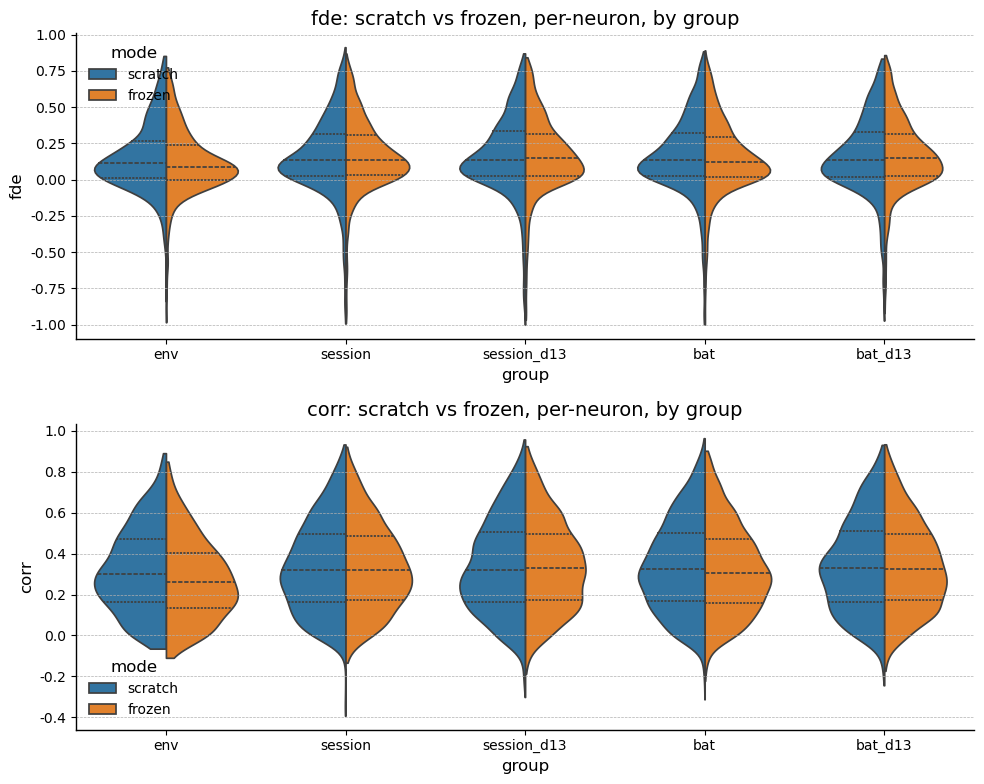

In [ ]:
def load_results(groups):
    """Concatenate per-group result pkls. Older pkls used mode='finetune'
    for the frozen-core sweep; rename to 'frozen' so downstream code is uniform."""
    parts = [pd.read_pickle(os.path.join(OUT_ROOT, g, f'results_{g}.pkl'))
             for g in groups
             if os.path.exists(os.path.join(OUT_ROOT, g, f'results_{g}.pkl'))]
    if not parts:
        return pd.DataFrame()
    df = pd.concat(parts, ignore_index=True)
    if 'mode' in df.columns:
        df['mode'] = df['mode'].replace({'finetune': 'frozen'})
    return df


df_all = load_results(['env', 'session', 'session_d13', 'bat', 'bat_d13'])
if df_all.empty:
    print('No results yet; flip RUN_INITIAL = True and rerun.')
else:
    fig, axes = plt.subplots(len(['fde', 'corr']), 1, figsize=(10, 8))
    for ax, metric in zip(axes, ['fde', 'corr']):
        sns.violinplot(data=crop_for_plot(df_all, metric),
                       x='group', y=metric, hue='mode',
                       split=True, inner='quartile', ax=ax, cut=0)
        ax.set_title(f'{metric}: scratch vs frozen, per-neuron, by group')
    plt.tight_layout()


    def paired_stats(df, metric, level):
        """level in {'neuron','session'}. Pairs frozen vs scratch."""
        if level == 'neuron':
            wide = (df.pivot_table(
                index=['group', 'heldout', 'target_session', 'neuron_idx'],
                columns='mode', values=metric)
                .dropna(subset=['frozen', 'scratch']).reset_index())
            n_col = 'n_neurons'
        else:
            wide = (df.groupby(['group', 'heldout', 'target_session', 'mode'])[metric]
                      .median().unstack('mode')
                      .dropna(subset=['frozen', 'scratch']).reset_index())
            n_col = 'n_sessions'

        def _row(g):
            d = g['frozen'] - g['scratch']
            return pd.Series({
                n_col: len(g),
                'med_frozen': g['frozen'].median(),
                'med_scratch': g['scratch'].median(),
                'med_diff': d.median(),
                'frac_frozen_wins': (d > 0).mean(),
                'wilcoxon_p_two': wilcoxon_p(d),
                'wilcoxon_p_ft_gt': wilcoxon_p(d, alternative='greater'),
            })
        return wide.groupby('group').apply(_row).reset_index()


    for metric in ('fde', 'corr'):
        for level in ('neuron', 'session'):
            print(f'=== Paired stats — {metric}, {level}-level ===')
            display(paired_stats(crop_for_plot(df_all, metric), metric, level).round(4))


## Scaling: foundation accuracy vs # training sessions

For each universe (`SESSIONS` or `SESSIONS_D13`), train foundation models on
size-N stratified subsets (`N ∈ {2, 4, 8, N_full}`, 10 random subsamples per
N≥2; coverage repair guarantees every session appears in ≥1 subset) and
evaluate each subset model on every session it contains. The N=1 baseline
reuses the per-target scratch checkpoints from the `session` / `session_d13`
sweeps (no retraining).

In [ ]:
def stratified_subsamples(universe, N, n_samples, rng):
    """Round-robin anchors + coverage-repair so every session appears in ≥1 subset."""
    universe = list(universe); N_full = len(universe)
    assert N <= N_full
    anchors = list(universe); rng.shuffle(anchors)
    samples = []
    for i in range(n_samples):
        anchor = anchors[i % N_full]
        rest = list(rng.choice([s for s in universe if s != anchor],
                                size=N - 1, replace=False))
        samples.append(sorted([anchor] + rest))
    missing = sorted(set(universe) - set().union(*samples))
    for m in missing:
        best = None
        for si, sub in enumerate(samples):
            if m in sub: continue
            for ji, s in enumerate(sub):
                others = sum(1 for oi, o in enumerate(samples) if oi != si and s in o)
                if others >= 1 and (best is None or others > best[2]):
                    best = (si, ji, others)
        assert best is not None, f'cannot insert {m} without dropping coverage'
        si, ji, _ = best
        samples[si][ji] = m; samples[si] = sorted(samples[si])
    assert set().union(*samples) == set(universe)
    return samples


def scaling_specs(group, scratch_group, universe, sizes=(2, 4, 8),
                   n_samples=10, seed=SEED):
    universe = list(universe); N_full = len(universe)
    rng = np.random.default_rng(seed)
    sub_map = {(N_full, 0): list(universe)}
    for N in sizes:
        for sid, sub in enumerate(stratified_subsamples(universe, N, n_samples, rng)):
            sub_map[(N, sid)] = sub

    specs = []
    # N=1 reuses scratch checkpoints (eval-only).
    for t in universe:
        specs.append(dict(
            name=f'scaling_{group}:N1:{t}', mode='scratch',
            target_session=t, source_sessions=(),
            save_path=ckpt_path(scratch_group, t, suffix=f'__{t}_scratch'),
            eval_target=t,
            row_meta={'scaling_group': group, 'n_sessions': 1, 'sample_id': 0},
        ))
    # N>=2 + N_full: foundation on subset, eval on every contained session.
    for (N, sid), sub in sub_map.items():
        specs.append(dict(
            name=f'scaling_{group}:N{N}:s{sid}', mode='foundation',
            source_sessions=tuple(sub), save_path=scaling_path(group, N, sid),
            eval_target=list(sub),
            row_meta={'scaling_group': group, 'n_sessions': N, 'sample_id': sid},
        ))
    return specs


SCALING_GROUPS = [('session', SESSIONS), ('session_d13', SESSIONS_D13)]

RUN_SCALING = True
if RUN_SCALING:
    for g, univ in SCALING_GROUPS:
        df = run_specs(scaling_specs(g, g, univ), label=f'scaling_{g}')
        df.to_pickle(os.path.join(OUT_ROOT, f'scaling_{g}', f'results_scaling_{g}.pkl'))


### Scaling analysis: per-target curves + paired Wilcoxon vs N=1

=== Scaling paired stats (fde, vs N=1) ===


/tmp/ipykernel_2980860/3611619236.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return long.groupby(['scaling_group', 'n_sessions']).apply(_row).reset_index()
/tmp/ipykernel_2980860/3611619236.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return long.groupby(['scaling_group', 'n_sessions']).apply(_row).reset_index()
/tmp/ipykernel_2980860/3611619236.py:26: DeprecationWarning: DataFrameGroupBy.

,scaling_group,n_sessions,n_targets,mean_diff,frac_better,wilcoxon_p_two
0,session,2,18.0,-0.0003,0.5000,0.8650
1,session,4,18.0,-0.0013,0.6111,0.9323
2,session,8,18.0,0.0030,0.5000,0.7660
3,session,18,18.0,-0.0040,0.3889,0.5226
4,session_d13,2,14.0,0.0047,0.4286,0.7148
5,session_d13,4,14.0,0.0130,0.4286,0.9515
6,session_d13,8,14.0,0.0162,0.5000,1.0000
7,session_d13,14,14.0,0.0157,0.4286,1.0000


=== Scaling paired stats (corr, vs N=1) ===


/tmp/ipykernel_2980860/3611619236.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return long.groupby(['scaling_group', 'n_sessions']).apply(_row).reset_index()


,scaling_group,n_sessions,n_targets,mean_diff,frac_better,wilcoxon_p_two
0,session,2,18.0,-0.0007,0.5000,0.8650
1,session,4,18.0,-0.0052,0.2778,0.2121
2,session,8,18.0,0.0071,0.4444,0.9661
3,session,18,18.0,0.0005,0.3333,0.4171
4,session_d13,2,14.0,-0.0090,0.3571,0.2412
5,session_d13,4,14.0,-0.0052,0.3571,0.1726
6,session_d13,8,14.0,-0.0031,0.2857,0.1531
7,session_d13,14,14.0,-0.0041,0.4286,0.2958


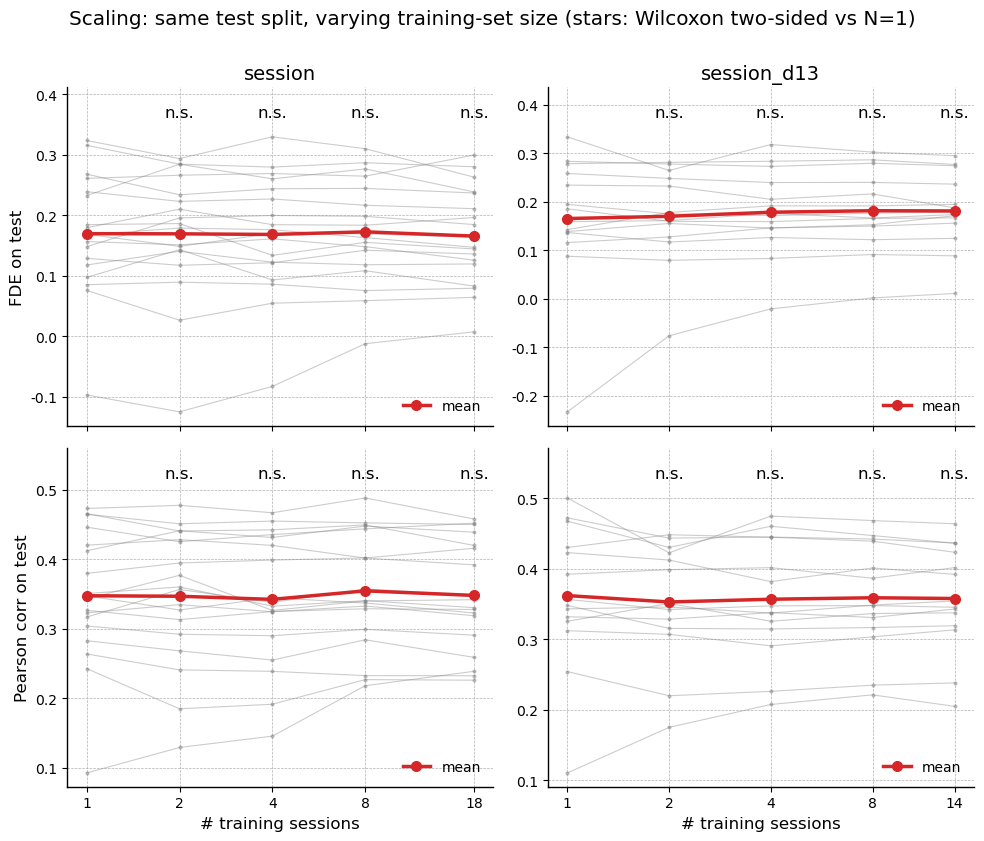

In [ ]:
sc_paths = [(g, os.path.join(OUT_ROOT, f'scaling_{g}', f'results_scaling_{g}.pkl'))
            for g, _ in SCALING_GROUPS]
df_sc = pd.concat([pd.read_pickle(p) for _, p in sc_paths if os.path.exists(p)],
                   ignore_index=True)
if df_sc.empty:
    print('No scaling results yet.')
else:
    # per-target value at each (group, N): median across neurons → mean across subsamples.
    per_T = (df_sc.groupby(['scaling_group', 'n_sessions', 'sample_id', 'target_session'])
                  [['fde', 'corr']].median()
                  .groupby(level=['scaling_group', 'n_sessions', 'target_session']).mean()
                  .reset_index())

    def scaling_paired(per_T, metric):
        base = (per_T.query('n_sessions == 1')
                      .set_index(['scaling_group', 'target_session'])[metric]
                      .rename('baseline'))
        long = (per_T.query('n_sessions > 1')
                      .join(base, on=['scaling_group', 'target_session']).dropna())

        def _row(g):
            d = g[metric] - g['baseline']
            return pd.Series({'n_targets': len(g), 'mean_diff': d.mean(),
                               'frac_better': (d > 0).mean(),
                               'wilcoxon_p_two': wilcoxon_p(d)})
        return long.groupby(['scaling_group', 'n_sessions']).apply(_row).reset_index()

    groups = sorted(per_T['scaling_group'].unique())
    metrics = [('fde', 'FDE on test'), ('corr', 'Pearson corr on test')]
    fig, axes = plt.subplots(len(metrics), len(groups),
                              figsize=(5 * len(groups), 4.2 * len(metrics)),
                              sharex='col', squeeze=False)
    for r, (metric, ylabel) in enumerate(metrics):
        stats = scaling_paired(per_T, metric)
        for c, grp in enumerate(groups):
            ax = axes[r, c]
            sub = per_T[per_T['scaling_group'] == grp]
            ns = sorted(sub['n_sessions'].unique())
            # per-target lines (gray)
            for t, g in sub.groupby('target_session'):
                g = g.set_index('n_sessions').reindex(ns)
                ax.plot(ns, g[metric], color='gray', alpha=0.4, lw=0.8, marker='.', ms=4)
            # mean across targets (red)
            ax.plot(ns, sub.groupby('n_sessions')[metric].mean().reindex(ns),
                    color='C3', lw=2.5, marker='o', ms=7, label='mean')
            # stars
            gs = stats.query('scaling_group == @grp').set_index('n_sessions')
            y_top = sub[metric].max(); y_bot = sub[metric].min()
            for n in ns[1:]:
                p = gs.loc[n, 'wilcoxon_p_two'] if n in gs.index else np.nan
                ax.text(n, y_top + 0.06 * (y_top - y_bot),
                        p_to_stars(p), ha='center', va='bottom')
            ax.set_ylim(top=y_top + 0.18 * (y_top - y_bot))
            ax.set_xscale('log', base=2); ax.set_xticks(ns); ax.set_xticklabels(ns)
            if r == len(metrics) - 1: ax.set_xlabel('# training sessions')
            if r == 0: ax.set_title(grp)
            if c == 0: ax.set_ylabel(ylabel)
            ax.legend(frameon=False, loc='lower right')
    fig.suptitle('Scaling: same test split, varying training-set size '
                 '(stars: Wilcoxon two-sided vs N=1)', y=1.0)
    plt.tight_layout()

    for metric, _ in metrics:
        print(f'=== Scaling paired stats ({metric}, vs N=1) ===')
        display(scaling_paired(per_T, metric).round(4))


## Full vs transfer vs scratch (per-neuron)

Three regimes evaluated on the same per-session test split:
- **full** — N=18 foundation (from the scaling sweep, all 18 sessions seen).
- **transfer** — frozen-core finetune of the 17-session foundation.
- **scratch** — single-session model, no transfer.

                    fde          corr        
                  count  median count  median
condition                                    
full (N=18)        2253  0.1290  2253  0.3151
scratch            2253  0.1293  2253  0.3188
transfer (frozen)  2253  0.1341  2253  0.3214


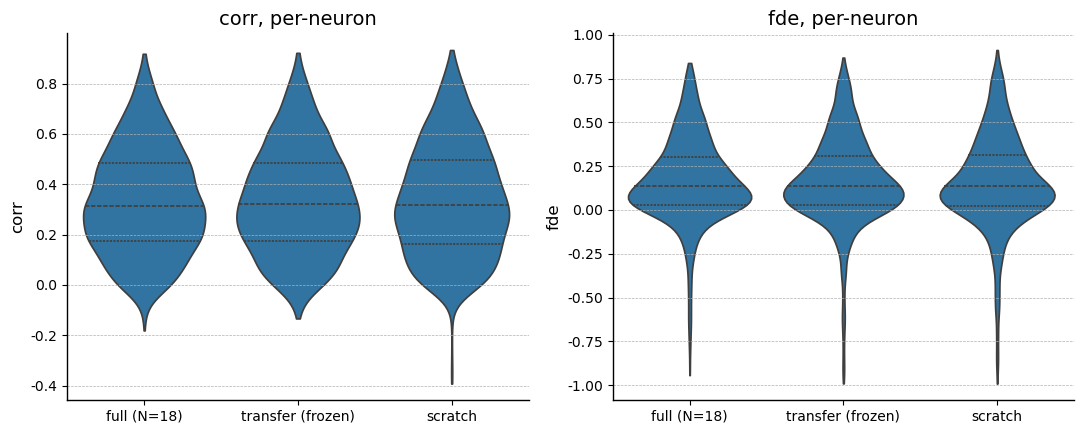

In [ ]:
N_FULL = len(SESSIONS)

# full: scaling N=18 model, evaluated per-session — read from scaling_session pkl.
sc_path = os.path.join(OUT_ROOT, 'scaling_session', 'results_scaling_session.pkl')
df_session = (load_results(['session']) if os.path.exists(
    os.path.join(OUT_ROOT, 'session', 'results_session.pkl')) else pd.DataFrame())
df_full = (pd.read_pickle(sc_path).query('n_sessions == @N_FULL')
                 if os.path.exists(sc_path) else pd.DataFrame())

if df_session.empty or df_full.empty:
    print('Need both session and scaling_session N=18 results.')
else:
    df_cmp = pd.concat([
        df_full.assign(condition=f'full (N={N_FULL})')[['target_session', 'neuron_idx', 'fde', 'corr', 'condition']],
        df_session.query('mode == "frozen"').assign(condition='transfer (frozen)')[
            ['target_session', 'neuron_idx', 'fde', 'corr', 'condition']],
        df_session.query('mode == "scratch"').assign(condition='scratch')[
            ['target_session', 'neuron_idx', 'fde', 'corr', 'condition']],
    ], ignore_index=True)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, metric in zip(axes, ['corr', 'fde']):
        sns.violinplot(data=crop_for_plot(df_cmp, metric),
                       x='condition', y=metric, inner='quartile', ax=ax, cut=0,
                       order=[f'full (N={N_FULL})', 'transfer (frozen)', 'scratch'])
        ax.set_xlabel(''); ax.set_title(f'{metric}, per-neuron')
    plt.tight_layout()

    print(df_cmp.groupby('condition')[['fde', 'corr']].agg(['count', 'median']).round(4))


# 2 × 5 matrix: data fraction × training mode

Universe: all 18 sessions in `SESSIONS`. For each target, evaluate five
training regimes (`full / frozen / lowlr / highlr / scratch`) at two
target-session training-data fractions (**100 %** and **25 %**); other 17
sessions stay at 100 %. Test set is always the target's full test split.

Reused checkpoints when the cell matches:
- `(full,    100%)` → `scaling_session/…N18_s0.pth`
- `(frozen,  100%)` → `session/…__{target}_finetune.pth`
- `(scratch, 100%)` → `session/…__{target}_scratch.pth`

The remaining 7 cells × 18 = 126 trainings are unique to this section.

In [ ]:
MODES_2X5     = ['full', 'frozen', 'lowlr', 'highlr', 'scratch']
FRACTIONS_2X5 = [1.0, 0.25]


def _full_n18_path():
    return scaling_path('session', len(SESSIONS), 0)


def _2x5_save_path(target, mode, fraction):
    """Reuse existing checkpoints when the (mode, 100%) cell matches; otherwise
    a new twoxfive_path slot."""
    if fraction == 1.0:
        if mode == 'full':    return _full_n18_path()
        if mode == 'frozen':  return ckpt_path('session', target, suffix=f'__{target}_finetune')
        if mode == 'scratch': return ckpt_path('session', target, suffix=f'__{target}_scratch')
    return twoxfive_path(target, mode, int(round(fraction * 100)))


def twoxfive_specs():
    specs = []
    for target in SESSIONS:
        sources_minus_t = [s for s in SESSIONS if s != target]
        f_path = ckpt_path('session', target)
        for fraction in FRACTIONS_2X5:
            pct = int(round(fraction * 100))
            t_train = subsample_train_dataloader(
                dataloaders['train'][target], fraction, seed=SEED) if fraction < 1.0 else None
            for mode in MODES_2X5:
                save_path = _2x5_save_path(target, mode, fraction)
                meta = {'fraction_pct': pct}
                base = dict(name=f'2x5:{target}:f{pct}:{mode}',
                             save_path=save_path, eval_target=target,
                             target_train_dl=t_train, row_meta=meta)
                if mode == 'full':
                    spec = dict(base, mode='foundation',
                                 target_session=target,
                                 source_sessions=tuple(SESSIONS),
                                 row_meta={**meta, 'mode': 'full'})
                elif mode == 'scratch':
                    spec = dict(base, mode='scratch', target_session=target,
                                 source_sessions=(), wd_grid=WD_SCRATCH_GRID)
                else:
                    spec = dict(base, mode=mode, target_session=target,
                                 source_sessions=tuple(sources_minus_t),
                                 foundation_path=f_path)
                specs.append(spec)
    return specs


RUN_2X5 = True
if RUN_2X5:
    df_2x5 = run_specs(twoxfive_specs(), label='2x5')
    df_2x5.to_pickle(os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl'))
    print(df_2x5.groupby(['fraction_pct', 'mode'])['fde'].describe()[['count', 'mean', '50%']])


### 2x5 results — violins

Two figures:
- **Split violin**: `hue='fraction'` so 100 % and 25 % sit side-by-side per mode.
- **Plain violin grid**: `row=metric × col=fraction`, no hue.

=== Paired neuron-level fde contrasts ===


,fraction_pct,contrast,n,median,frac_a_better,wilcoxon_p_two
0,25,full − frozen,2158,0.0082,0.5463,0.0000
1,25,full − lowlr,2170,-0.0085,0.4558,0.0004
2,25,full − highlr,2172,0.0111,0.5520,0.0000
3,25,full − scratch,2168,0.0162,0.5701,0.0000
4,25,lowlr − frozen,2170,0.0156,0.6014,0.0000
5,25,lowlr − scratch,2178,0.0249,0.6171,0.0000
6,25,highlr − frozen,2167,0.0012,0.5048,0.2933
7,25,highlr − lowlr,2186,-0.0163,0.4209,0.0000
8,25,highlr − scratch,2183,0.0097,0.5364,0.0006
9,25,frozen − scratch,2163,0.0080,0.5289,0.0000


=== Paired neuron-level corr contrasts ===


,fraction_pct,contrast,n,median,frac_a_better,wilcoxon_p_two
0,25,full − frozen,2253,0.0084,0.5526,0.0000
1,25,full − lowlr,2253,-0.0035,0.4647,0.0155
2,25,full − highlr,2253,0.0008,0.5064,0.6813
3,25,full − scratch,2253,0.0206,0.5961,0.0000
4,25,lowlr − frozen,2253,0.0118,0.6014,0.0000
5,25,lowlr − scratch,2253,0.0223,0.6138,0.0000
6,25,highlr − frozen,2253,0.0087,0.5544,0.0000
7,25,highlr − lowlr,2253,-0.0023,0.4745,0.0034
8,25,highlr − scratch,2253,0.0182,0.5970,0.0000
9,25,frozen − scratch,2253,0.0078,0.5393,0.0000


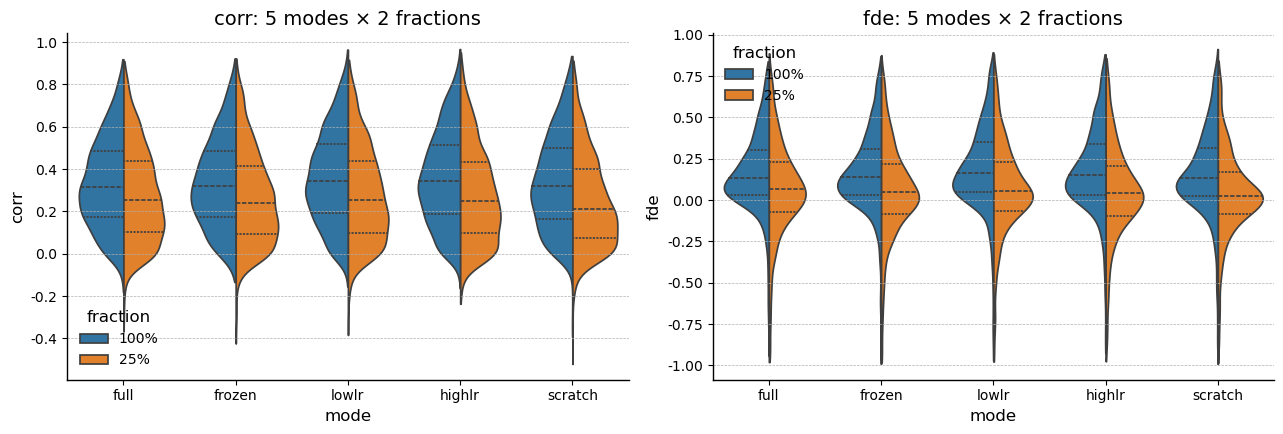

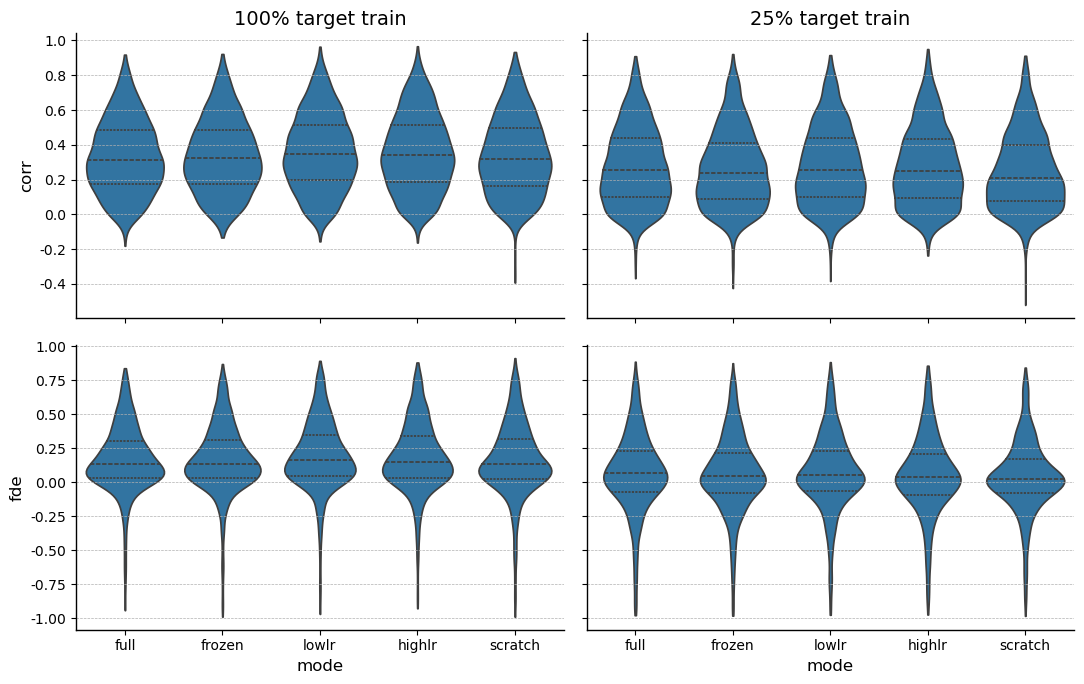

In [65]:
df_2x5 = pd.read_pickle(os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl'))
df_2x5 = df_2x5.assign(fraction=df_2x5['fraction_pct'].astype(int).astype(str) + '%')

# Split violins, one panel per metric.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ['corr', 'fde']):
    sns.violinplot(data=crop_for_plot(df_2x5, metric),
                   x='mode', y=metric, hue='fraction',
                   order=MODES_2X5, hue_order=['100%', '25%'],
                   split=True, inner='quartile', ax=ax, cut=0)
    ax.set_title(f'{metric}: {len(MODES_2X5)} modes × 2 fractions')
plt.tight_layout()

# Plain violins, row=metric × col=fraction.
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex='col', sharey='row')
for r, metric in enumerate(['corr', 'fde']):
    for c, fr in enumerate(['100%', '25%']):
        ax = axes[r, c]
        sub = crop_for_plot(df_2x5.query('fraction == @fr'), metric)
        sns.violinplot(data=sub, x='mode', y=metric, order=MODES_2X5,
                       inner='quartile', ax=ax, cut=0)
        if r == 0: ax.set_title(f'{fr} target train')
        if c == 0: ax.set_ylabel(metric)
plt.tight_layout()

# Paired neuron-level Wilcoxon contrasts within each fraction.
def paired_2x5(df, metric):
    wide = df.pivot_table(index=['target_session', 'neuron_idx', 'fraction_pct'],
                           columns='mode', values=metric)
    contrasts = [('full','frozen'), ('full','lowlr'), ('full','highlr'),
                  ('full','scratch'), ('lowlr','frozen'), ('lowlr','scratch'),
                  ('highlr','frozen'), ('highlr','lowlr'), ('highlr','scratch'),
                  ('frozen','scratch')]
    out = []
    for fr_pct, g in wide.groupby('fraction_pct'):
        for a, b in contrasts:
            if a not in g or b not in g: continue
            d = (g[a] - g[b]).dropna()
            if len(d) == 0: continue
            out.append({'fraction_pct': int(fr_pct), 'contrast': f'{a} − {b}',
                         'n': len(d), 'median': d.median(),
                         'frac_a_better': (d > 0).mean(),
                         'wilcoxon_p_two': wilcoxon_p(d)})
    return pd.DataFrame(out)

for metric in ('fde', 'corr'):
    print(f'=== Paired neuron-level {metric} contrasts ===')
    display(paired_2x5(crop_for_plot(df_2x5, metric), metric).round(4))


### 2x5 results — per-neuron transfer-vs-scratch scatter

Per-neuron scatter (each dot = one neuron) for FDE and corr, faceted by
contrast (`frozen / lowlr / highlr` vs `scratch`) × fraction (100% / 25%).
Above the y = x diagonal ⇒ transfer mode beats scratch on that neuron.

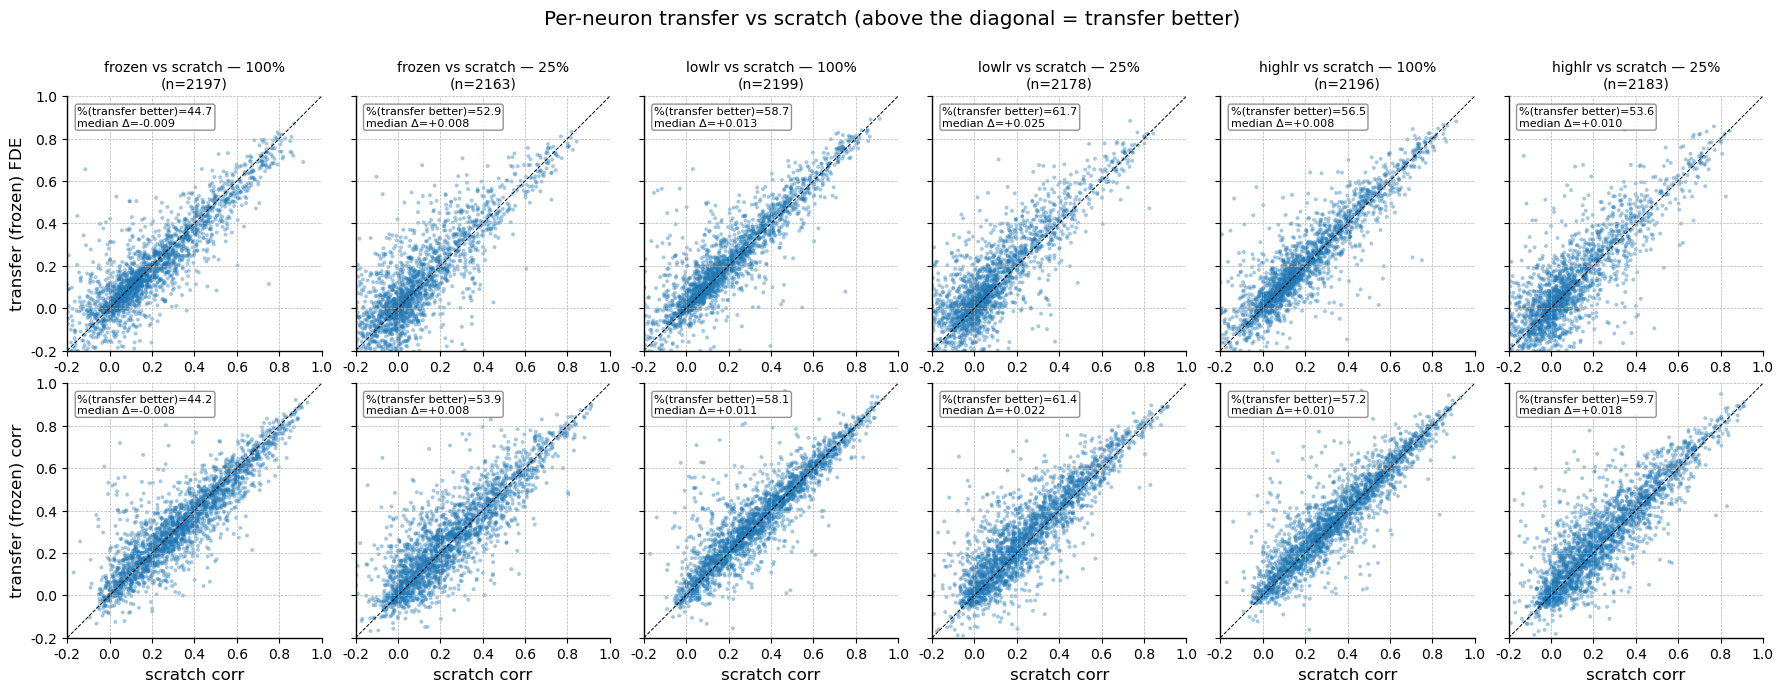

In [66]:
df_2x5 = pd.read_pickle(os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl'))
contrasts = [('frozen', 'scratch'), ('lowlr', 'scratch'), ('highlr', 'scratch')]
fractions = [100, 25]
metric_specs = [('fde', 'FDE', (-0.2, 1.0)), ('corr', 'corr', (-0.2, 1.0))]

n_rows, n_cols = len(metric_specs), len(contrasts) * len(fractions)
fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(3.0 * n_cols, 3.4 * n_rows),
                          sharex='row', sharey='row')
for r, (metric, mlabel, (lo, hi)) in enumerate(metric_specs):
    wide = (crop_for_plot(df_2x5, metric)
              .pivot_table(index=['target_session', 'neuron_idx', 'fraction_pct'],
                            columns='mode', values=metric))
    c = 0
    for a, b in contrasts:
        for fr in fractions:
            ax = axes[r, c]
            sub = wide.xs(fr, level='fraction_pct').dropna(subset=[a, b])
            if sub.empty:
                ax.set_visible(False); c += 1; continue
            ax.scatter(sub[b], sub[a], s=8, alpha=0.4, edgecolors='none')
            ax.plot([lo, hi], [lo, hi], 'k--', lw=0.7)
            ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
            frac_better = float((sub[a] > sub[b]).mean())
            med_d = float((sub[a] - sub[b]).median())
            if r == 0:
                ax.set_title(f'{a} vs {b} — {fr}%\n(n={len(sub)})', fontsize=10)
            if r == n_rows - 1: ax.set_xlabel(f'{b} {mlabel}')
            if c == 0:          ax.set_ylabel(f'transfer ({a}) {mlabel}')
            ax.text(0.04, 0.96,
                    f'%(transfer better)={100*frac_better:.1f}\nmedian Δ={med_d:+.3f}',
                    transform=ax.transAxes, va='top', ha='left', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.85))
            c += 1
fig.suptitle('Per-neuron transfer vs scratch (above the diagonal = transfer better)', y=1.005)
plt.tight_layout()


### 2x5 — per-session %(transfer FDE > scratch FDE)

For each session and (mode, fraction), the % of its neurons where transfer
beats scratch on FDE. Lines per session (hue=session); two layout variants
(swap of x and col) so you can read across either axis. Stars are paired
Wilcoxon vs 50 %; brackets between adjacent x positions are paired
Wilcoxon between modes (or fractions, in the swap).

Per-session %(transfer FDE > scratch):


fraction_pct              25                        100                   
mode                   frozen  full highlr lowlr frozen  full highlr lowlr
target_session                                                            
Dataset_1_32622_231007   41.8  58.2   39.8  56.1   50.0  38.8   44.9  55.1
Dataset_1_32622_231009   60.7  70.5   57.4  68.9   55.7  55.7   54.1  73.8
Dataset_1_32622_231010   48.6  40.5   56.8  59.5   37.8  37.8   67.6  59.5
Dataset_2_14445_231208   57.2  63.8   63.8  69.7   27.3  33.1   59.1  52.6
Dataset_2_14445_231209   46.1  60.8   52.0  65.7   36.3  35.3   62.7  61.8
Dataset_2_14611_231208   50.0  53.7   50.6  56.2   45.7  46.3   57.9  60.4
Dataset_2_14611_231209   75.4  67.2   44.8  64.9   59.4  48.9   39.8  57.1
Dataset_3_00000_240402   57.8  62.3   57.0  65.0   39.0  42.2   44.8  45.7
Dataset_3_00000_240403   50.4  47.8   56.5  65.2   35.7  35.7   55.7  49.6
Dataset_3_00000_240404   44.3  52.6   57.7  63.9   43.3  36.1   63.9  62.9
Dataset_3_00000_240405   45.3  46.7   41.3  58.7   22.7  38.7   60.0  58.7
Dataset_3_14543_240419   40.8  44.1   45.3  48.0   57.9  60.7   59.6  60.7
Dataset_3_14543_240420   59.2  63.2   44.7  65.8   51.3  55.3   69.7  63.2
Dataset_3_14543_240421   50.8  49.2   64.6  64.6   60.0  70.8   83.1  83.1
Dataset_3_29959_240402   48.9  51.5   50.0  58.6   46.6  48.5   53.0  59.8
Dataset_3_29959_240403   56.4  50.3   70.5  67.1   44.3  40.3   59.1  65.1
Dataset_3_29959_240404   44.6  47.9   49.6  52.9   36.4  34.7   49.6  53.7
Dataset_3_29959_240405   45.8  71.0   46.7  46.7   43.9  43.0   56.1  48.6

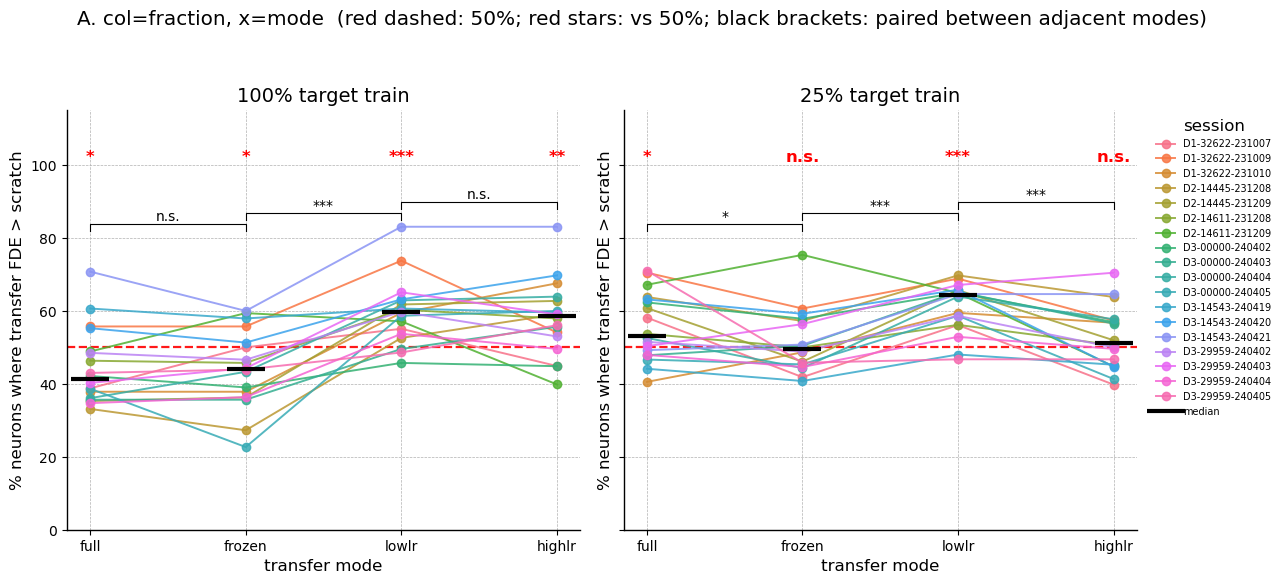

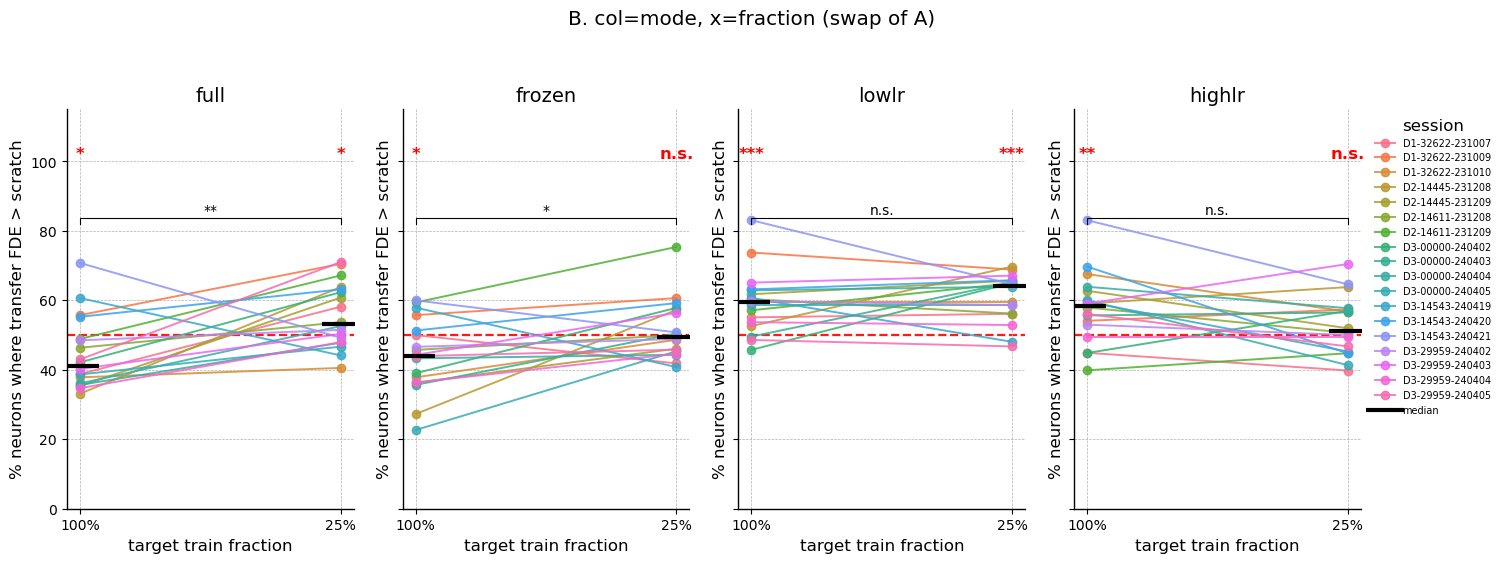

In [67]:
df_2x5 = pd.read_pickle(os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl'))
modes = ['full', 'frozen', 'lowlr', 'highlr']
fractions = [100, 25]
src = crop_for_plot(df_2x5, 'fde')
piv = src.pivot_table(index=['target_session', 'fraction_pct', 'neuron_idx'],
                       columns='mode', values='fde')

# %(mode > scratch) per (session, fraction, mode)
pct_long = (piv.gt(piv['scratch'], axis=0).reset_index()
                 .melt(id_vars=['target_session', 'fraction_pct', 'neuron_idx'],
                        value_vars=modes, var_name='mode', value_name='better')
                 .groupby(['target_session', 'fraction_pct', 'mode'])['better']
                 .agg(['sum', 'count']).reset_index())
pct_long['pct_better'] = 100 * pct_long['sum'] / pct_long['count']
pct_long['session_label'] = pct_long['target_session'].apply(
    lambda s: 'D{}-{}-{}'.format(*s.split('_')[1:4]))

label_order = sorted(pct_long['session_label'].unique())
palette = dict(zip(label_order, sns.color_palette('husl', n_colors=len(label_order))))


def _add_bracket(ax, x1, x2, y, star, h=1.8):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], 'k-', lw=0.8, clip_on=False)
    ax.text((x1 + x2) / 2, y + h + 0.2, star, ha='center', va='bottom',
            fontsize=10, clip_on=False)


def panel(ax, wide, x_levels, x_label):
    """Draw lines (one per session) + median ticks + 50% line + stars."""
    for label, row in wide.iterrows():
        if row.isna().any(): continue
        ax.plot(x_levels, row.values, marker='o', color=palette[label],
                alpha=0.85, lw=1.4, label=label)
    ax.plot(x_levels, wide.median().values, marker='_', ms=28, color='k', lw=0,
            mew=3, label='median')
    ax.axhline(50, color='red', lw=1.6, ls='--', alpha=0.9, zorder=0)
    ax.set_ylim(0, 115); ax.set_xlabel(x_label)
    ax.set_ylabel('% neurons where transfer FDE > scratch')
    # vs 50% stars
    for i, lvl in enumerate(x_levels):
        v = wide[lvl].dropna().values
        if len(v):
            ax.text(i, 100, p_to_stars(wilcoxon_p(v - 50)), ha='center',
                    va='bottom', fontsize=12, color='red', fontweight='bold')
    # adjacent paired stars
    for k in range(len(x_levels) - 1):
        valid = wide[[x_levels[k], x_levels[k + 1]]].dropna()
        if len(valid):
            p = wilcoxon_p(valid[x_levels[k]].values - valid[x_levels[k + 1]].values)
            _add_bracket(ax, k, k + 1, 82 + 3 * k, p_to_stars(p))


# Plot A: col = fraction, x = mode
fig, axes = plt.subplots(1, len(fractions), figsize=(6.5 * len(fractions), 5.6),
                          sharey=True)
for ax, fr in zip(np.atleast_1d(axes), fractions):
    wide = (pct_long.query('fraction_pct == @fr')
                      .pivot(index='session_label', columns='mode', values='pct_better')
                      .reindex(label_order)[modes])
    panel(ax, wide, modes, 'transfer mode')
    ax.set_title(f'{fr}% target train')
axes[-1].legend(title='session', bbox_to_anchor=(1.02, 1), loc='upper left',
                 fontsize=7, frameon=False)
fig.suptitle('A. col=fraction, x=mode  (red dashed: 50%; red stars: vs 50%; '
             'black brackets: paired between adjacent modes)', y=1.04)
plt.tight_layout()


# Plot B: col = mode, x = fraction (swap of A)
fig, axes = plt.subplots(1, len(modes), figsize=(3.8 * len(modes), 5.4),
                          sharey=True)
fr_xlabels = [f'{f}%' for f in fractions]
for ax, m in zip(np.atleast_1d(axes), modes):
    wide = (pct_long.query('mode == @m')
                      .pivot(index='session_label', columns='fraction_pct', values='pct_better')
                      .reindex(label_order)[fractions])
    wide.columns = fr_xlabels
    panel(ax, wide, fr_xlabels, 'target train fraction')
    ax.set_title(m)
axes[-1].legend(title='session', bbox_to_anchor=(1.02, 1), loc='upper left',
                 fontsize=7, frameon=False)
fig.suptitle('B. col=mode, x=fraction (swap of A)', y=1.04)
plt.tight_layout()


print('Per-session %(transfer FDE > scratch):')
display(pct_long.pivot_table(index='target_session',
                              columns=['fraction_pct', 'mode'],
                              values='pct_better').round(1))


### 2x5 — per-session ΔFDE swarm with Wilcoxon-vs-0 stars

Small dots = sessions, large dots = bat medians, each panel a fraction.

Wilcoxon vs 0 across sessions:


,fraction_pct,mode,n_sessions,median_delta,wilcoxon_p_two
0,100,full,18,-0.0117,0.0814
1,100,frozen,18,-0.0071,0.1297
2,100,lowlr,18,0.0132,0.0003
3,100,highlr,18,0.0089,0.0077
4,25,full,18,0.0135,0.0056
5,25,frozen,18,0.0021,0.5798
6,25,lowlr,18,0.0230,0.0000
7,25,highlr,18,0.0035,0.1297


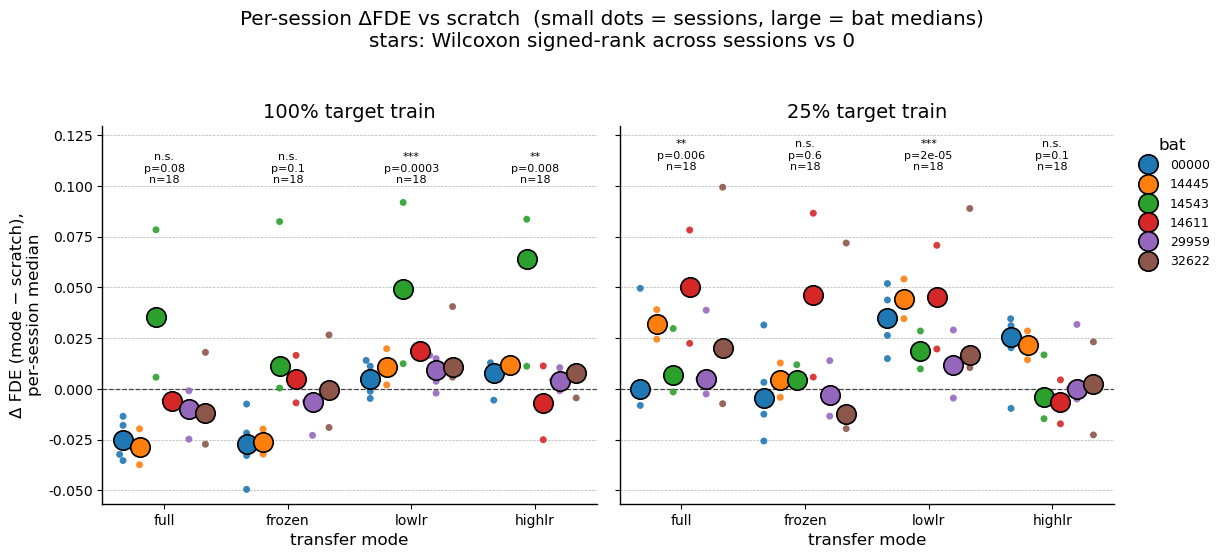

In [68]:
df_2x5 = pd.read_pickle(os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl'))
src = crop_for_plot(df_2x5, 'fde')
piv = src.pivot_table(index=['target_session', 'fraction_pct', 'neuron_idx'],
                       columns='mode', values='fde')
transfer_modes = ['full', 'frozen', 'lowlr', 'highlr']

# per-session median ΔFDE = mode - scratch
sess_long = (piv[transfer_modes].sub(piv['scratch'], axis=0)
                  .groupby(['target_session', 'fraction_pct']).median()
                  .stack().rename('delta').reset_index().rename(columns={'level_2': 'mode'}))
sess_long['bat'] = sess_long['target_session'].apply(bat_of)
# per-bat median (over sessions)
bat_long = (sess_long.groupby(['bat', 'fraction_pct', 'mode'])['delta']
                       .median().reset_index())

bats = sorted(sess_long['bat'].unique())
palette = dict(zip(bats, sns.color_palette('tab10', n_colors=len(bats))))
fractions = [100, 25]

fig, axes = plt.subplots(1, len(fractions), figsize=(6.2 * len(fractions), 5.4),
                          sharey=True)
stat_rows = []
for ax, fr in zip(np.atleast_1d(axes), fractions):
    s = sess_long.query('fraction_pct == @fr')
    b = bat_long.query('fraction_pct == @fr')
    sns.swarmplot(data=s, x='mode', y='delta', hue='bat',
                   order=transfer_modes, hue_order=bats, palette=palette,
                   size=5, ax=ax, dodge=True, alpha=0.9, legend=False)
    sns.swarmplot(data=b, x='mode', y='delta', hue='bat',
                   order=transfer_modes, hue_order=bats, palette=palette,
                   size=14, ax=ax, dodge=True, edgecolor='black', linewidth=1.2)
    ax.axhline(0, color='k', lw=0.9, ls='--', alpha=0.7)
    ax.set_title(f'{fr}% target train')
    ax.set_xlabel('transfer mode')
    ax.set_ylabel('Δ FDE (mode − scratch),\nper-session median')

    y_max = float(s['delta'].max()); y_span = max(y_max - float(s['delta'].min()), 1e-3)
    y_text = y_max + 0.06 * y_span
    for i, m in enumerate(transfer_modes):
        v = s.loc[s['mode'] == m, 'delta'].values
        p = wilcoxon_p(v); n = len(v)
        ax.text(i, y_text,
                f'{p_to_stars(p)}\np={p:.1g}\nn={n}' if np.isfinite(p) else f'(n={n})',
                ha='center', va='bottom', fontsize=8)
        stat_rows.append({'fraction_pct': fr, 'mode': m, 'n_sessions': n,
                           'median_delta': float(np.median(v)) if n else np.nan,
                           'wilcoxon_p_two': p})
    ax.set_ylim(top=y_text + 0.18 * y_span)

for ax in np.atleast_1d(axes)[:-1]:
    if ax.get_legend(): ax.get_legend().remove()
np.atleast_1d(axes)[-1].legend(title='bat', bbox_to_anchor=(1.02, 1),
                                 loc='upper left', fontsize=9, frameon=False)
fig.suptitle('Per-session ΔFDE vs scratch  (small dots = sessions, large = bat medians)\n'
             'stars: Wilcoxon signed-rank across sessions vs 0', y=1.03)
plt.tight_layout()

print('Wilcoxon vs 0 across sessions:')
display(pd.DataFrame(stat_rows).round(4))


### 2x5 — Δ histograms: (mode − scratch) at neuron / session / bat levels

For each transfer mode (`full`, `frozen`, `lowlr`, `highlr`), three
histograms of the difference vs the per-neuron `scratch` baseline:

- **neuron level** — one delta per (session, neuron); Wilcoxon vs 0 across all neurons
- **session level** — median Δ across neurons in each session, one value per session;
  Wilcoxon vs 0 across the 18 sessions
- **bat level** — average within bats of the per-session medians, one value per
  bat; Wilcoxon vs 0 across the 6 bats (controls for unequal sessions / bat)

Stars: `*** p<0.001 / ** p<0.01 / * p<0.05 / n.s.`. The bat level inherently
performs the within-bat aggregation requested for the session and bat
comparisons; the session column is also shown so you can see how across-session
dispersion narrows after the bat-level pooling.

One figure per (fraction, metric) → 4 figures total.

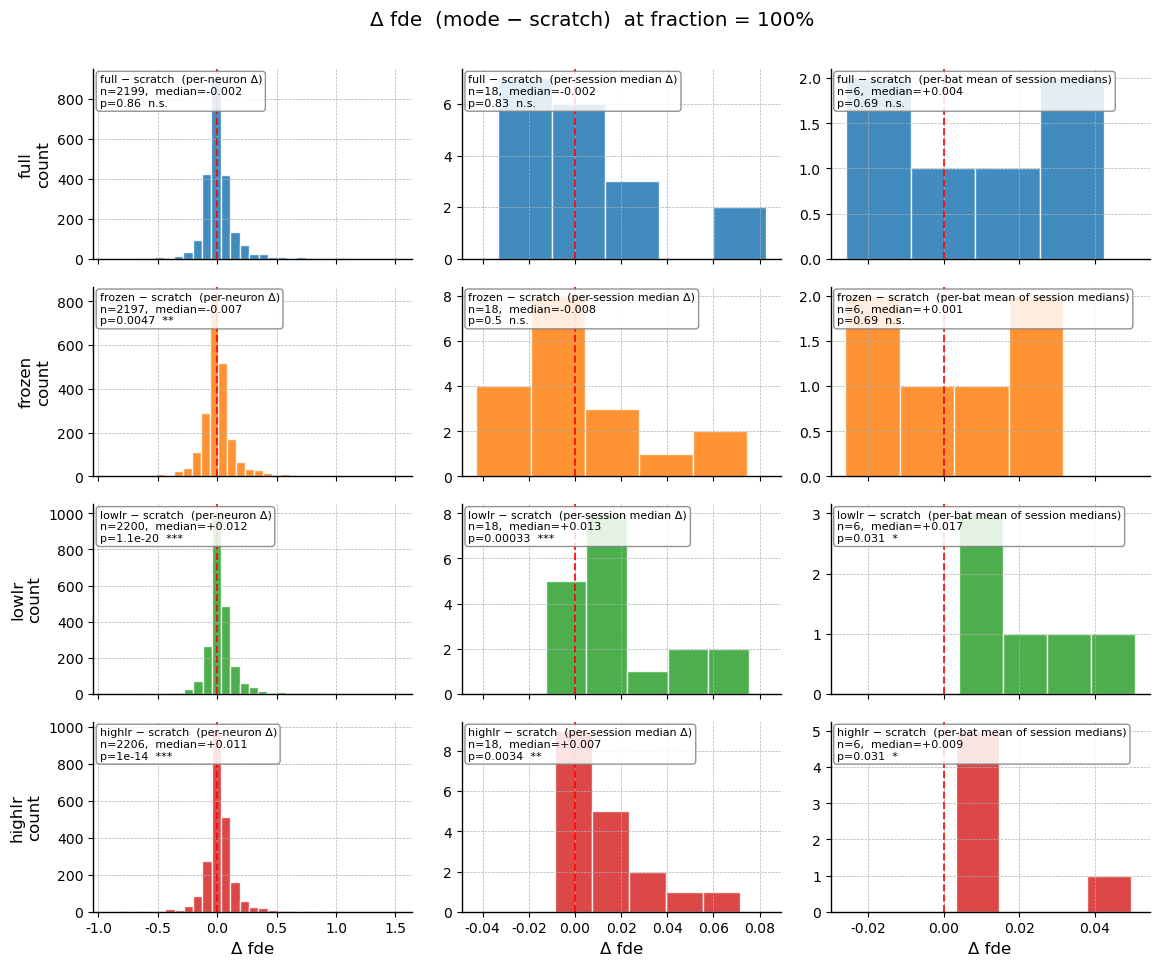

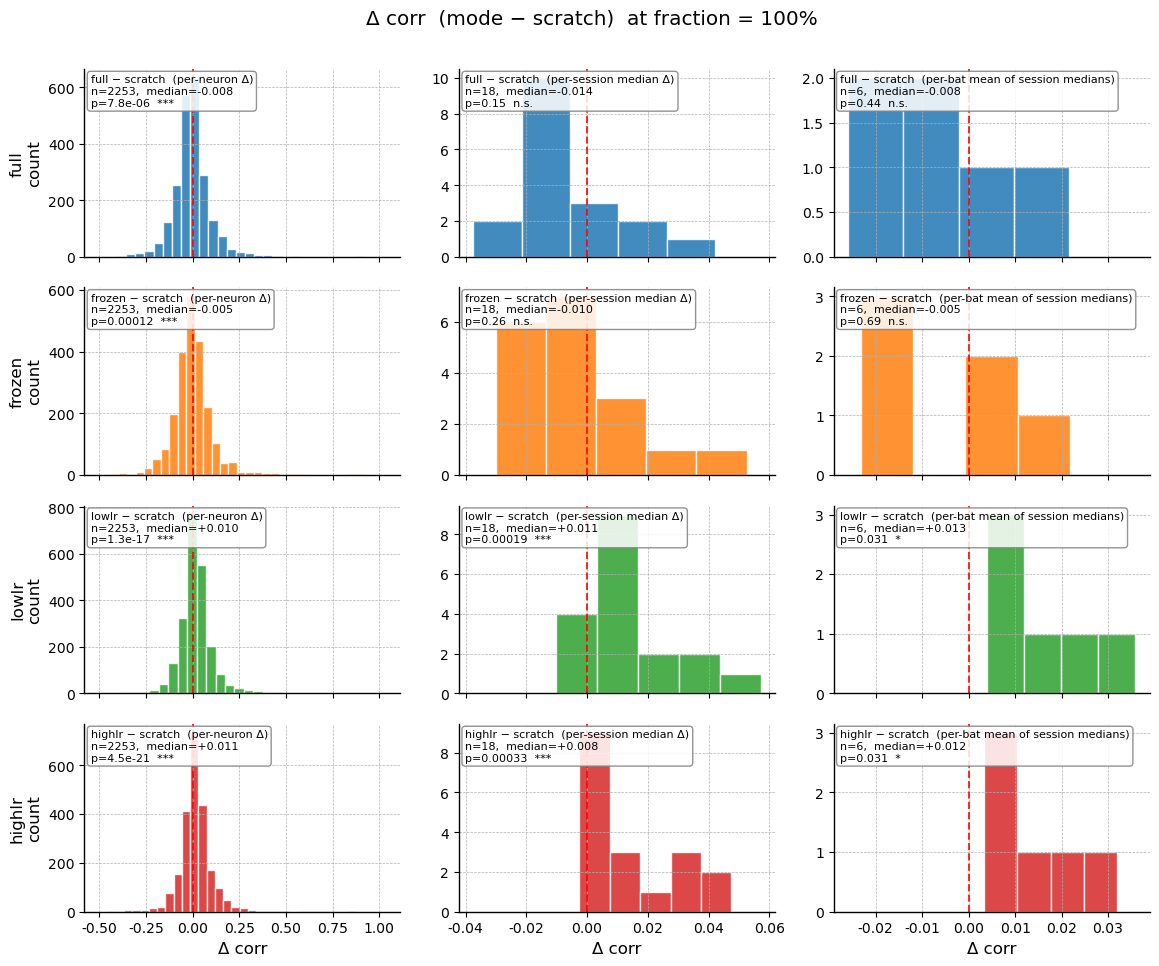

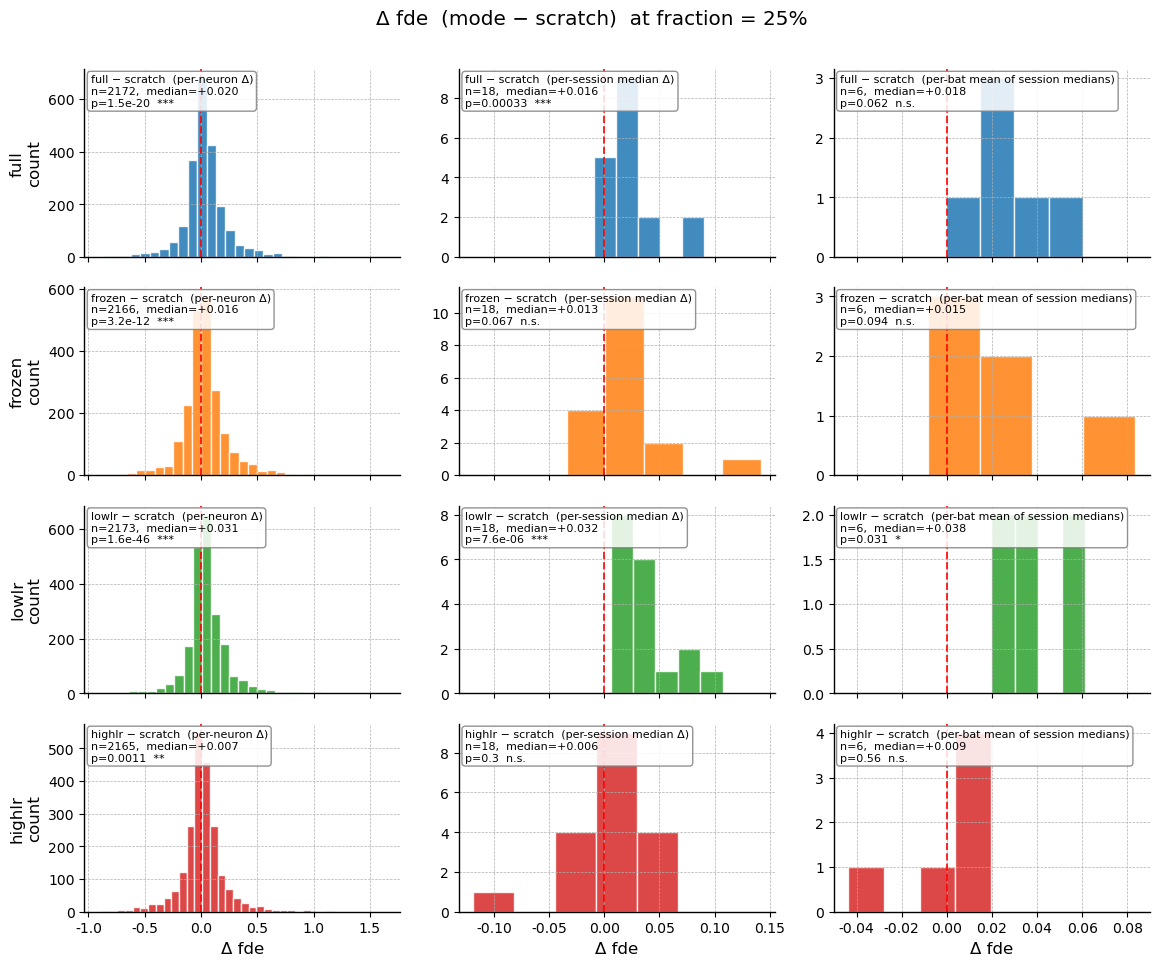

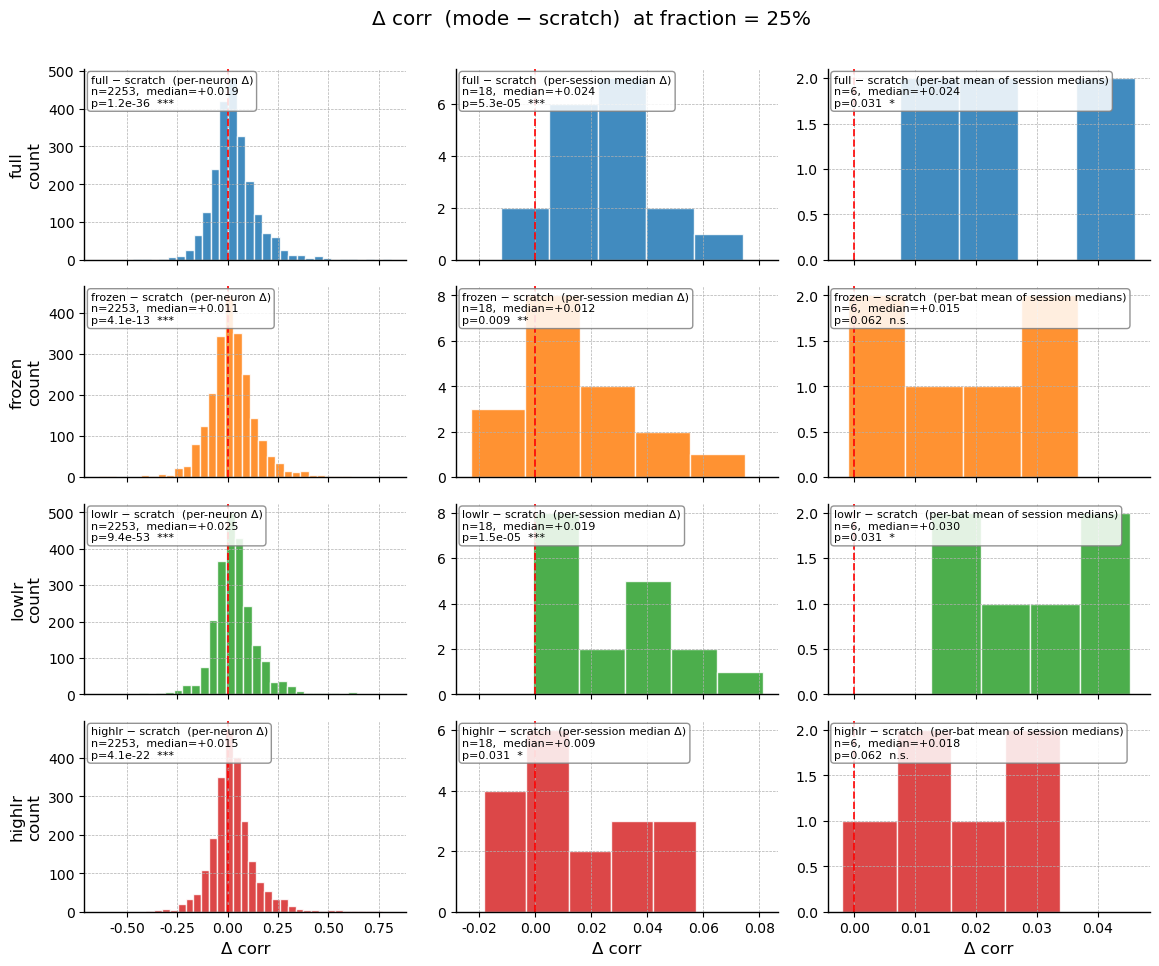

In [30]:
def diff_histograms(df, fraction, metric, scratch='scratch',
                     transfer_modes=('full', 'frozen', 'lowlr', 'highlr')):
    """Histograms of (mode − scratch) at neuron / session / bat levels.

    Long-form pipeline (no per-loop pivots): one .pivot_table over (target_session,
    neuron_idx) × mode → subtract scratch column-wise → groupby for the two
    aggregated levels."""
    src = crop_for_plot(df.query('fraction_pct == @fraction'), metric)
    piv = src.pivot_table(index=['target_session', 'neuron_idx'],
                           columns='mode', values=metric)
    diff_neuron = (piv[list(transfer_modes)]
                     .sub(piv[scratch], axis=0)
                     .dropna(how='all'))                          # MultiIndex (session, neuron)
    diff_session = diff_neuron.groupby('target_session').median()  # one row per session
    diff_bat = (diff_session.assign(bat=diff_session.index.map(bat_of))
                              .groupby('bat')[list(transfer_modes)].mean())  # one row per bat

    levels = [
        ('neuron',  diff_neuron,  'per-neuron Δ'),
        ('session', diff_session, 'per-session median Δ'),
        ('bat',     diff_bat,     'per-bat mean of session medians'),
    ]

    fig, axes = plt.subplots(len(transfer_modes), len(levels),
                              figsize=(4.0 * len(levels), 2.4 * len(transfer_modes)),
                              sharex='col')
    for r, mode in enumerate(transfer_modes):
        for c, (lvl_name, df_lvl, lvl_desc) in enumerate(levels):
            ax = axes[r, c]
            v = df_lvl[mode].dropna().values
            if len(v) == 0:
                ax.set_visible(False); continue
            n_bins = max(4, min(30, len(v) // 4 + 1))
            ax.hist(v, bins=n_bins, alpha=0.85, color=f'C{r}', edgecolor='white')
            ax.axvline(0, color='red', ls='--', lw=1.4, alpha=0.85)
            p = wilcoxon_p(v); stars = p_to_stars(p)
            ax.text(0.02, 0.97,
                    f'{mode} − {scratch}  ({lvl_desc})\n'
                    f'n={len(v)},  median={np.median(v):+.3f}\n'
                    f'p={p:.2g}  {stars}',
                    transform=ax.transAxes, va='top', ha='left', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.3', fc='white',
                              ec='gray', alpha=0.85))
            if r == len(transfer_modes) - 1:
                ax.set_xlabel(f'Δ {metric}')
            if c == 0:
                ax.set_ylabel(f'{mode}\ncount')
    fig.suptitle(f'Δ {metric}  (mode − {scratch})  at fraction = {fraction}%',
                 y=1.005)
    plt.tight_layout()


df_2x5 = pd.read_pickle(os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl'))
for fr in [100, 25]:
    for met in ('fde', 'corr'):
        diff_histograms(df_2x5, fr, met)


# Cross-experiment lowlr vs scratch (and scratch_lowlr control)

Train **lowlr** finetune for each target in each of the 5 transfer settings,
plus a **scratch_lowlr** control (single-session model trained with the
same param-group LR config as lowlr but from random init — `lowlr` minus the
foundation initialisation).

Reuse rules:
- For setting `session`, the per-target lowlr@100 % checkpoint already
  exists in `out/transfer/twoxfive/` (same model). Specs point there directly,
  so no retraining.
- The per-heldout *foundation* models from the initial-transfer cells are
  reused as init for the lowlr finetune.

In [69]:
def _lowlr_save_path(group, target):
    """For 'session', point at the existing 2x5 lowlr@100 % checkpoint."""
    if group == 'session':
        twox = twoxfive_path(target, 'lowlr', 100)
        if os.path.exists(twox):
            return twox
    return ckpt_path(group, target, suffix=f'__{target}_lowlr')


def lowlr_specs(group, held_groups, universe, sessions_in):
    specs = []
    for heldout in held_groups:
        targets = sessions_in(heldout)
        sources = [s for s in universe if s not in targets]
        f_path = ckpt_path(group, heldout)
        for t in targets:
            specs.append(dict(
                name=f'{group}:lowlr:{heldout}:{t}', mode='lowlr',
                target_session=t, source_sessions=tuple(sources),
                foundation_path=f_path, save_path=_lowlr_save_path(group, t),
                eval_target=t, row_meta={'group': group, 'heldout': heldout},
            ))
    return specs


def scratch_lowlr_specs():
    return [dict(
        name=f'scratch_lowlr:{t}', mode='lowlr',
        target_session=t, source_sessions=(), foundation_path=None,
        save_path=scratch_lowlr_path(t),
        eval_target=t, wd_grid=WD_SCRATCH_GRID,
        row_meta={'mode': 'scratch_lowlr'},
    ) for t in SESSIONS]


RUN_LOWLR_ALL = False
if RUN_LOWLR_ALL:
    for g, held, univ, sess_in in SETTINGS_INITIAL:
        df = run_specs(lowlr_specs(g, held, univ, sess_in), label=f'lowlr-{g}')
        df.to_pickle(os.path.join(OUT_ROOT, g, f'results_{g}_lowlr.pkl'))
    df_sl = run_specs(scratch_lowlr_specs(), label='scratch_lowlr')
    df_sl.to_pickle(os.path.join(SCRATCH_LOWLR_DIR, 'results_scratch_lowlr.pkl'))


## Cross-experiment plots

For each of the 5 transfer settings, two contrasts:
1. `lowlr − scratch` (does foundation init + slow-LR core help?)
2. `lowlr − scratch_lowlr` (slow-LR controlled out → isolates foundation-init)

Plus per-neuron scatter for both.

Setting order: env / session_d13 / bat_d13 / session / bat (rough complexity).

Per-group summary (Wilcoxon two-sided vs 0):


/tmp/ipykernel_2980860/1552597188.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([group_label[g] for g in group_order],
/tmp/ipykernel_2980860/1552597188.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([group_label[g] for g in group_order],


,metric,group,n_sessions,median_delta,wilcoxon_p_two
0,fde,env,4,0.0036,0.6250
1,fde,session_d13,14,0.0117,0.0107
2,fde,bat_d13,14,0.0148,0.0001
3,fde,session,18,0.0132,0.0003
4,fde,bat,18,0.0107,0.0023
5,corr,env,4,0.0023,0.8750
6,corr,session_d13,14,0.0098,0.0107
7,corr,bat_d13,14,0.0132,0.0001
8,corr,session,18,0.0072,0.0010
9,corr,bat,18,0.0114,0.0099


Per-group summary (Wilcoxon two-sided vs 0):


/tmp/ipykernel_2980860/1552597188.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([group_label[g] for g in group_order],
/tmp/ipykernel_2980860/1552597188.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([group_label[g] for g in group_order],


,metric,group,n_sessions,median_delta,wilcoxon_p_two
0,fde,env,4,0.0083,0.8750
1,fde,session_d13,14,0.0171,0.0017
2,fde,bat_d13,14,0.0164,0.0012
3,fde,session,18,0.0154,0.0000
4,fde,bat,18,0.0174,0.0005
5,corr,env,4,0.0097,0.6250
6,corr,session_d13,14,0.0187,0.0001
7,corr,bat_d13,14,0.0186,0.0006
8,corr,session,18,0.0178,0.0000
9,corr,bat,18,0.0172,0.0001


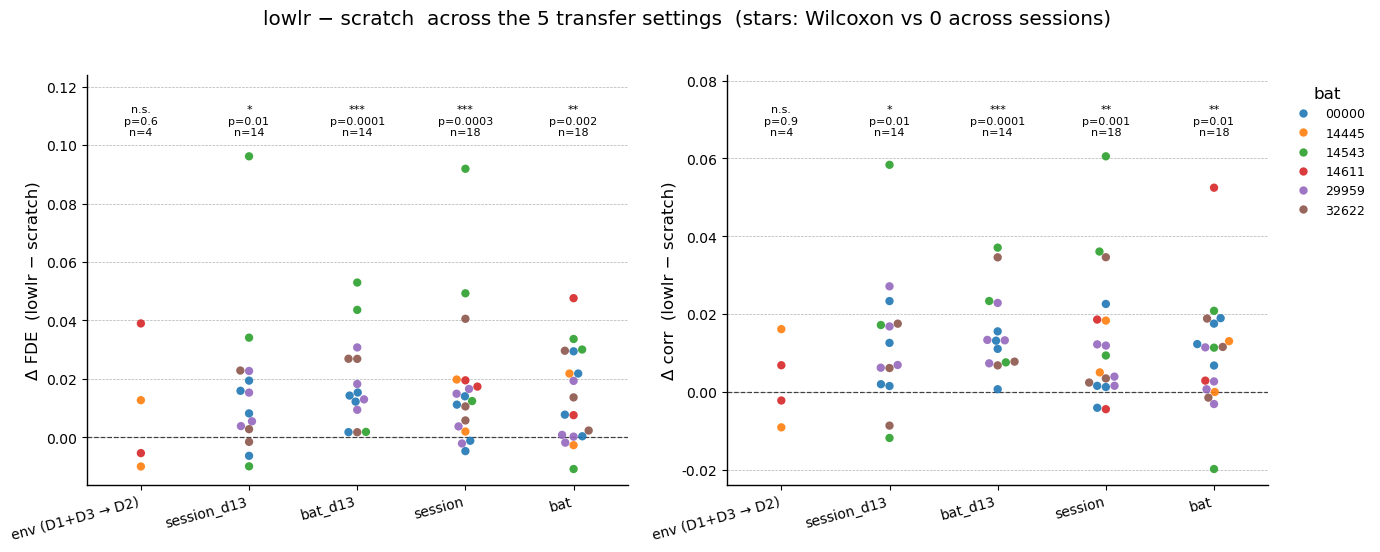

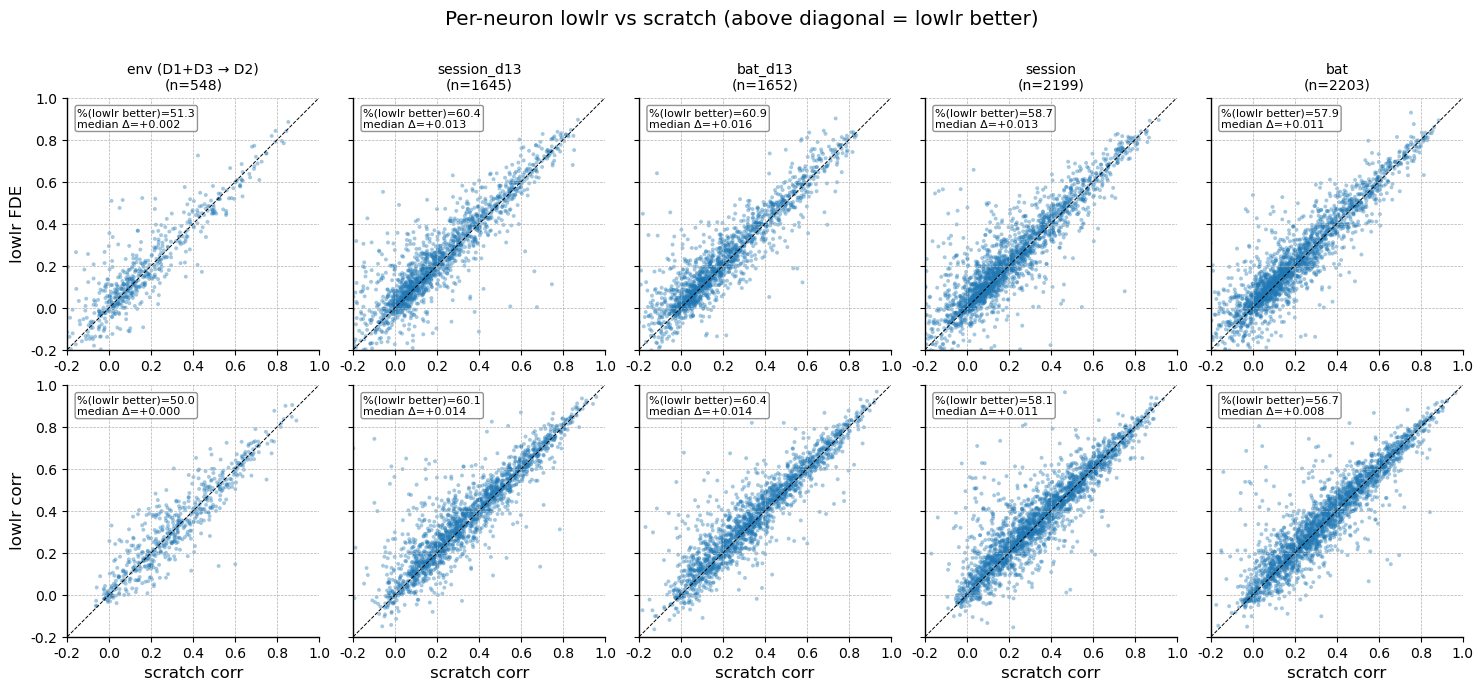

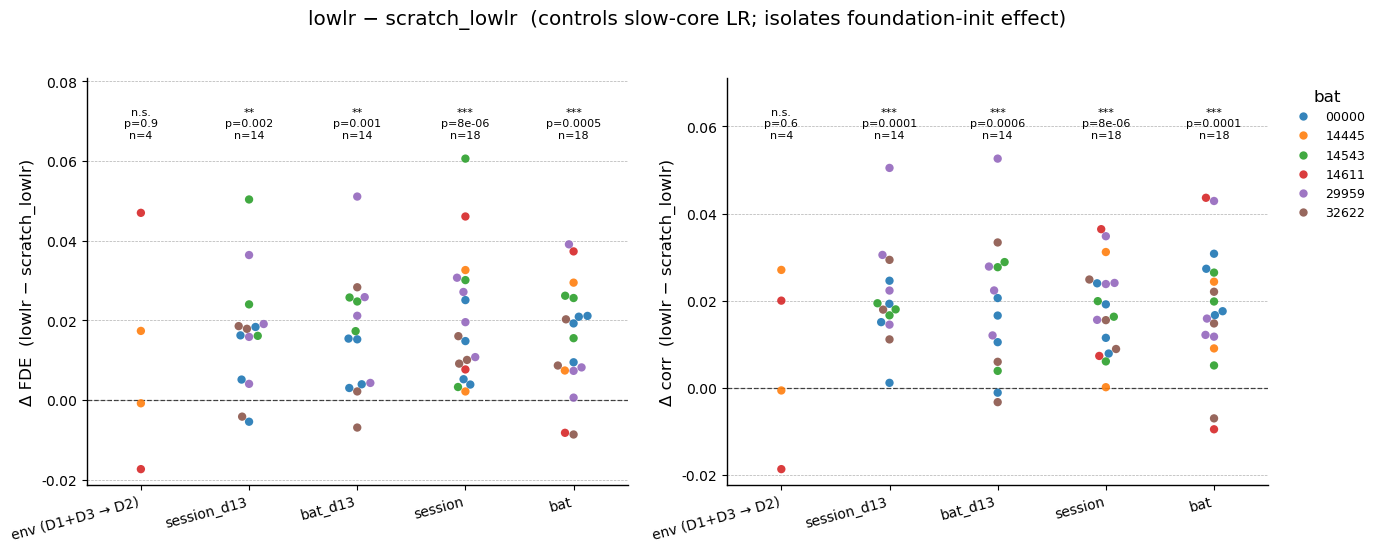

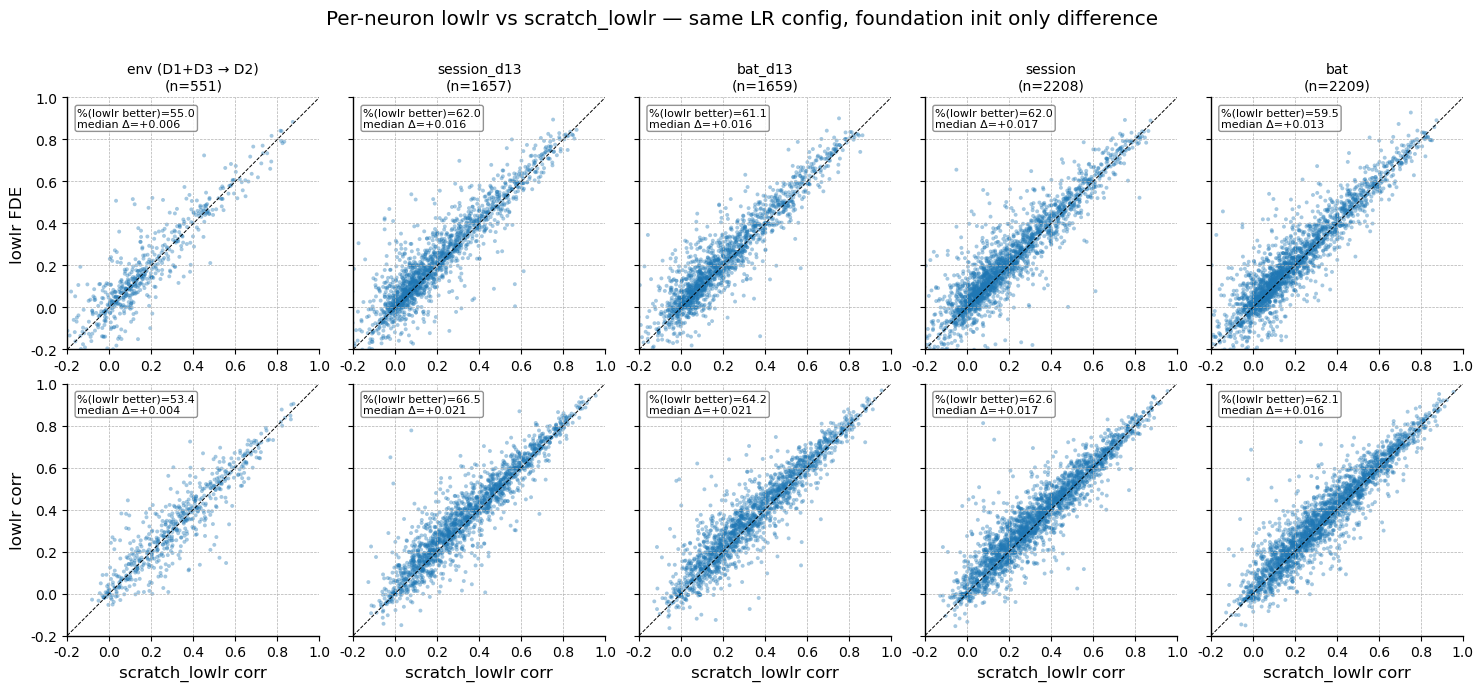

In [70]:
GROUPS_X = [
    ('env',          'env (D1+D3 → D2)'),
    ('session_d13',  'session_d13'),
    ('bat_d13',      'bat_d13'),
    ('session',      'session'),
    ('bat',          'bat'),
]
group_order = [g for g, _ in GROUPS_X]
group_label = dict(GROUPS_X)


def _load_per_group(filename):
    return pd.concat([
        pd.read_pickle(os.path.join(OUT_ROOT, g, filename.format(g=g)))
        for g, _ in GROUPS_X
        if os.path.exists(os.path.join(OUT_ROOT, g, filename.format(g=g)))
    ], ignore_index=True)


def _per_session_delta(df_left, df_right, metric, on, drop_right_group=False):
    """Pair df_left vs df_right per neuron on `on` cols, take per-session
    median (group, target_session). df_right may lack 'group' (scratch_lowlr
    is per-target only); we just drop_right_group=True in that case."""
    l = crop_for_plot(df_left, metric)[['group', 'target_session', 'neuron_idx', metric]]
    r_cols = ['target_session', 'neuron_idx', metric] if drop_right_group else \
              ['group', 'target_session', 'neuron_idx', metric]
    r = crop_for_plot(df_right, metric)[r_cols]
    paired = l.merge(r, on=on, suffixes=('_left', '_right'))
    paired['delta'] = paired[f'{metric}_left'] - paired[f'{metric}_right']
    sess = (paired.groupby(['group', 'target_session'])['delta']
                    .median().reset_index())
    sess['bat'] = sess['target_session'].map(bat_of)
    return sess


def swarm_compare(df_left, df_right, *, baseline_label, suptitle,
                   drop_right_group=False):
    """2-panel ΔFDE / Δcorr swarm: x=group, hue=bat, stars vs 0."""
    on = (['target_session', 'neuron_idx'] if drop_right_group
           else ['group', 'target_session', 'neuron_idx'])
    metric_specs = [('fde', 'Δ FDE'), ('corr', 'Δ corr')]
    sess = {m: _per_session_delta(df_left, df_right, m, on, drop_right_group)
            for m, _ in metric_specs}
    bats = sorted(set().union(*[s['bat'].unique() for s in sess.values()]))
    palette = dict(zip(bats, sns.color_palette('tab10', n_colors=len(bats))))

    fig, axes = plt.subplots(1, len(metric_specs),
                              figsize=(7.0 * len(metric_specs), 5.4), sharex=True)
    stat_rows = []
    for ax, (metric, ylabel) in zip(np.atleast_1d(axes), metric_specs):
        sub = sess[metric]
        sns.swarmplot(data=sub, x='group', y='delta', hue='bat',
                       order=group_order, hue_order=bats, palette=palette,
                       size=6, ax=ax, dodge=False, alpha=0.9)
        ax.axhline(0, color='k', lw=0.9, ls='--', alpha=0.7)
        y_max = float(sub['delta'].max())
        y_span = max(y_max - float(sub['delta'].min()), 1e-3)
        y_text = y_max + 0.06 * y_span
        # Wilcoxon vs 0 per group
        for i, g in enumerate(group_order):
            v = sub.loc[sub['group'] == g, 'delta'].values
            p = wilcoxon_p(v); n = len(v)
            ax.text(i, y_text,
                    f'{p_to_stars(p)}\np={p:.1g}\nn={n}' if np.isfinite(p) else f'(n={n})',
                    ha='center', va='bottom', fontsize=8)
            stat_rows.append({'metric': metric, 'group': g, 'n_sessions': n,
                               'median_delta': float(np.median(v)) if n else np.nan,
                               'wilcoxon_p_two': p})
        ax.set_ylim(top=y_text + 0.20 * y_span)
        ax.set_xticklabels([group_label[g] for g in group_order],
                            rotation=15, ha='right')
        ax.set_xlabel(''); ax.set_ylabel(f'{ylabel}  (lowlr − {baseline_label})')

    for ax in np.atleast_1d(axes)[:-1]:
        if ax.get_legend(): ax.get_legend().remove()
    np.atleast_1d(axes)[-1].legend(title='bat', bbox_to_anchor=(1.02, 1),
                                     loc='upper left', fontsize=9, frameon=False)
    fig.suptitle(suptitle, y=1.02)
    plt.tight_layout()
    print('Per-group summary (Wilcoxon two-sided vs 0):')
    display(pd.DataFrame(stat_rows).round(4))


def scatter_compare(df_left, df_right, *, baseline_label, suptitle,
                     drop_right_group=False):
    """2 (FDE, corr) × 5 (settings) per-neuron scatter, lowlr (y) vs baseline (x)."""
    on = (['target_session', 'neuron_idx'] if drop_right_group
           else ['group', 'target_session', 'neuron_idx'])
    metric_specs = [('fde', 'FDE', (-0.2, 1.0)), ('corr', 'corr', (-0.2, 1.0))]
    fig, axes = plt.subplots(len(metric_specs), len(group_order),
                              figsize=(3.0 * len(group_order), 3.4 * len(metric_specs)),
                              sharex='row', sharey='row')
    for r, (metric, mlabel, (lo, hi)) in enumerate(metric_specs):
        l = crop_for_plot(df_left, metric)[
            ['group', 'target_session', 'neuron_idx', metric]
        ].rename(columns={metric: 'y'})
        r_cols = (['target_session', 'neuron_idx', metric] if drop_right_group
                   else ['group', 'target_session', 'neuron_idx', metric])
        rt = crop_for_plot(df_right, metric)[r_cols].rename(columns={metric: 'x'})
        paired = l.merge(rt, on=on)
        for c, g in enumerate(group_order):
            ax = axes[r, c]
            sub = paired.query('group == @g')
            if sub.empty:
                ax.set_visible(False); continue
            ax.scatter(sub['x'], sub['y'], s=8, alpha=0.4, edgecolors='none')
            ax.plot([lo, hi], [lo, hi], 'k--', lw=0.7)
            ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
            frac_better = (sub['y'] > sub['x']).mean()
            med_d = (sub['y'] - sub['x']).median()
            if r == 0:
                ax.set_title(f'{group_label[g]}\n(n={len(sub)})', fontsize=10)
            if r == len(metric_specs) - 1: ax.set_xlabel(f'{baseline_label} {mlabel}')
            if c == 0:                      ax.set_ylabel(f'lowlr {mlabel}')
            ax.text(0.04, 0.96,
                    f'%(lowlr better)={100*frac_better:.1f}\nmedian Δ={med_d:+.3f}',
                    transform=ax.transAxes, va='top', ha='left', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.85))
    fig.suptitle(suptitle, y=1.005)
    plt.tight_layout()


# Load datasets once.
df_lowlr = _load_per_group('results_{g}_lowlr.pkl')
df_initial = _load_per_group('results_{g}.pkl')
df_scratch = df_initial[df_initial['mode'] == 'scratch'] if not df_initial.empty else df_initial
sl_path = os.path.join(SCRATCH_LOWLR_DIR, 'results_scratch_lowlr.pkl')
df_scratch_lowlr = pd.read_pickle(sl_path) if os.path.exists(sl_path) else pd.DataFrame()

if df_lowlr.empty or df_scratch.empty:
    print('Need lowlr + scratch results on disk.')
else:
    swarm_compare(df_lowlr, df_scratch, baseline_label='scratch',
                   suptitle='lowlr − scratch  across the 5 transfer settings  '
                            '(stars: Wilcoxon vs 0 across sessions)')
    scatter_compare(df_lowlr, df_scratch, baseline_label='scratch',
                     suptitle='Per-neuron lowlr vs scratch (above diagonal = lowlr better)')

    if not df_scratch_lowlr.empty:
        swarm_compare(df_lowlr, df_scratch_lowlr, baseline_label='scratch_lowlr',
                       drop_right_group=True,
                       suptitle='lowlr − scratch_lowlr  (controls slow-core LR; '
                                'isolates foundation-init effect)')
        scatter_compare(df_lowlr, df_scratch_lowlr, baseline_label='scratch_lowlr',
                         drop_right_group=True,
                         suptitle='Per-neuron lowlr vs scratch_lowlr — same LR config, '
                                  'foundation init only difference')
